In [1]:
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter, defaultdict
import os
import scipy.stats as stats
from scipy.special import logsumexp
import pandas as pd
import matplotlib.cm as cm
import math
import itertools
import random
from matplotlib.colors import TwoSlopeNorm, LinearSegmentedColormap
from random import random

from scipy.stats import linregress
from sklearn.linear_model import RANSACRegressor, LinearRegression, TheilSenRegressor
from scipy.stats import chi2_contingency, fisher_exact


import sys
sys.path.append('../src')

from em_clustering import (
    reassign_cells
)

from visualization import plot_overlap_matrix_figure

/home/ranade/miniconda3/lib/python3.6/site-packages/statsmodels/tools/_testing.py:19: FutureWarning: pandas.util.testing is deprecated. Use the functions in the public API at pandas.testing instead.
  import pandas.util.testing as tm


In [2]:
tumor ="t57"
infilename = f"../data/{tumor}/{tumor}.bin_count_table_all_cells.txt"
bincounts = pd.read_csv(infilename, sep="\t")
bincounts_no_WGS = pd.read_csv(f"../data/{tumor}/{tumor}.bincounts_without_WGS_segmentation.txt", sep="\t")


In [3]:
# Use ALL cells instead of filtered cells
all_cell_names = [col for col in bincounts.columns if col not in ['chrom', 'abstart', 'abend', 'lengths','loc.start','loc.end']]
cells = pd.read_csv(f"../data/{tumor}/{tumor}.not_broken_final_list.txt", header=None)[0].values


In [4]:
previous_A_df = pd.read_csv(f"../data/{tumor}/{tumor}_new_population_assignments_A.txt", sep="\t")
previous_B_df = pd.read_csv(f"../data/{tumor}/{tumor}_new_population_assignments_B.txt", sep="\t")

In [5]:
#len(previous_A_df), len(cells)

In [6]:
def make_random_seeds(q_data, num_seeds=10):
    """Generate multiple random seeds for EM initialization."""
    Seeds = []
    for i in range(num_seeds):
        s = []
        for j in range(len(q_data)):
            l2 = q_data.loc[j].values
            mi, mx = min(l2), max(l2)
            s.append([random() * (mx - mi) + mi, random() * (mx - mi) + mi])
        Seeds.append(s)
    return Seeds

In [7]:
def alg_on_best_of_seeds(all_data, num_seeds=1):
    """Run EM algorithm on multiple seeds and return best result."""
    q_data = all_data/all_data.sum(axis=0)
    Seeds = make_random_seeds(q_data, num_seeds)

    best_log_lik = -np.inf
    for s in Seeds:
        print("Trying new seed")
        logprob_NK, log_lik, mult_KV = EM_algorithm(all_data, s)
        if log_lik > best_log_lik:
            best_log_lik = log_lik
            best_logprob_NK = logprob_NK
            best_mult_KV = mult_KV
    
    return best_logprob_NK, best_log_lik, best_mult_KV

In [8]:
def EM_algorithm(data, s, Min_Diff=0.001, Max_Iter=20):
    """Core EM algorithm implementation."""
    obs_NV = np.array(data)[:,:].T
    log_likelihood = -np.inf
    
    mult_KV = np.array(s).T
    mult_KV = mult_KV / np.sum(mult_KV, axis=1)[:, np.newaxis]

    for i in range(Max_Iter):
        logmult_KV = np.log(mult_KV)
        logprob_NK = np.dot(obs_NV, logmult_KV.T)
        logsum_N = [logsumexp(list(x)) for x in logprob_NK]
        logprob_NK = np.add(logprob_NK, -np.array(logsum_N)[:, np.newaxis])

        membership_NK = np.exp(logprob_NK)
        log_likelihood_last = log_likelihood
        log_likelihood = np.sum(logsum_N)

        mult_KV = np.dot(membership_NK.T, obs_NV)
        mult_KV = mult_KV / np.sum(mult_KV, axis=1)[:, np.newaxis]
        
        log_diff = abs(log_likelihood-log_likelihood_last)
        if log_diff < Min_Diff:
            break
            
    if log_diff > 10*Min_Diff:
        return logprob_NK, -np.inf, mult_KV
    
    return logprob_NK, log_likelihood, mult_KV


In [9]:
def ratio_of_ratios_old(all_data, threshold=4/5, name=""):
    """Ratio of ratios analysis for population splitting."""
    logprob_NK, log_lik, mult_KV = alg_on_best_of_seeds(all_data)
    cluster1 = np.where(np.array([x-y for x,y in logprob_NK])>0)[0]
    cluster2 = np.where(np.array([x-y for x,y in logprob_NK])<0)[0]
    cells_1 = [all_data.columns[i] for i in cluster1]
    cells_2 = [all_data.columns[i] for i in cluster2]
    
    counts_1 = all_data[cells_1].sum(axis=1)
    counts_2 = all_data[cells_2].sum(axis=1)
    
    total_1 = np.sum(counts_1)
    total_2 = np.sum(counts_2)

    chi2_values = []
    for i in range(len(counts_1)):
        observed = np.array([
            [counts_1[i], total_1 - counts_1[i]],
            [counts_2[i], total_2 - counts_2[i]]
        ])
        chi2, p, dof, expected = chi2_contingency(observed, correction=False)
        chi2_values.append(chi2)
    chi2_values = np.array(chi2_values)
    top_indices = np.argsort(chi2_values)[-10:][::-1]
    bottom_indices = np.argsort(chi2_values)[:30]
    
    ratios_1 = []
    ratios_2 = []
    for i in top_indices:
        r1 = []
        r2 = []
        for j in bottom_indices:
            if j!=i:
                r1.append(counts_1[i]/counts_1[j])
                r2.append(counts_2[i]/counts_2[j])
        ratios_1.append(r1)
        ratios_2.append(r2)
    slopes = []
    fig,ax = plt.subplots(1, figsize=(10, 10))
    
    for r1, r2 in zip(ratios_1, ratios_2): 
        plt.scatter(r1, r2, alpha=0.5)
    for r1, r2 in zip(ratios_1, ratios_2): 
        model = RANSACRegressor(LinearRegression(fit_intercept=False)).fit(np.array(r1).reshape(-1, 1), np.array(r2))
        slopes.append(model.estimator_.coef_[0])
        x_fit = np.linspace(min(r1), max(r1), 100).reshape(-1, 1)
        y_fit = model.predict(x_fit)
        plt.plot(x_fit, y_fit, linestyle='dashed')

    x = np.linspace(0, 10, 50)
    plt.plot(x, x, color='black')  # y=x line 

    y = threshold * x
    plt.plot(x, y, color='grey')  # y=(4/5)x line
    y = (1/threshold) * x
    plt.plot(x, y, color='grey')  # y=(5/4)x line

    l1 = str(len(cells_1))
    l2 = str(len(cells_2))
    plt.title(f"Ratio of Ratios Plot {name}1({l1}) and {name}2({l2})")
    plt.xlim([0,10])
    plt.ylim([0,10])
    return slopes, top_indices, bottom_indices, cells_1, cells_2, mult_KV


In [10]:
def recursive_em_split_old(data, cell_list, mult_KV_param=None, threshold=3/4, max_depth=10, current_depth=0, name="A"):
    """
    Recursively splits cell populations using EM algorithm until slopes are within threshold.
    """
    print(f"{'  ' * current_depth}Processing population {name} with {len(cell_list)} cells")
    
    if mult_KV_param is None:
        current_data = data[cell_list]
        q_data = current_data / current_data.sum(axis=0)
        mult_KV_param = q_data.mean(axis=1).values
    
    threshold = min(threshold, 1/threshold)
    if current_depth >= max_depth:
        print(f"{'  ' * current_depth}Max depth reached for {name}")
        return {name: {'cells': cell_list, 'mult_KV': mult_KV_param}}
    
    if len(cell_list) < 50:
        print(f"{'  ' * current_depth}Population {name} too small to split")
        return {name: {'cells': cell_list, 'mult_KV': mult_KV_param}}
    
    try:
        current_data = data[cell_list]
        slopes, top_indices, bottom_indices, cells_1, cells_2, unassigned = ratio_of_ratios_old(current_data, threshold, name)
        
        max_slope = max(slopes)
        min_slope = min(slopes)
        
        print(f"{'  ' * current_depth}Slopes for {name}: max={max_slope:.3f}, min={min_slope:.3f}")
        
        if threshold <= min_slope and max_slope <= 1/threshold:
            print(f"{'  ' * current_depth}Split rejected for {name}: slopes between {threshold:.3f} and {1/threshold:.3f}")
            return {name: {'cells': cell_list, 'mult_KV': mult_KV_param}}
        
        if len(cells_1) < 25 or len(cells_2) < 25:
            print(f"{'  ' * current_depth}Split produces too small subpopulations for {name}")
            return {name: {'cells': cell_list, 'mult_KV': mult_KV_param}}
        
        print(f"{'  ' * current_depth}Split accepted for {name}: {len(cells_1)} + {len(cells_2)} cells")
        
        result = {}
        
        sub_result_1 = recursive_em_split_old(
            data, cells_1, mult_KV[0], threshold, max_depth, current_depth + 1, name + "1"
        )
        result.update(sub_result_1)
        
        sub_result_2 = recursive_em_split_old(
            data, cells_2, mult_KV[1], threshold, max_depth, current_depth + 1, name + "2"
        )
        result.update(sub_result_2)
        
        return result
        
    except Exception as e:
        print(f"{'  ' * current_depth}Error splitting {name}: {e}")
        return {name: {'cells': cell_list, 'mult_KV': mult_KV_param}}


In [11]:
# Prepare data
data = bincounts[["chrom", "abstart", "abend"] + all_cell_names].copy()
data["lengths"] = data["abend"] - data["abstart"]
all_data = data[cells].copy()
data_no_WGS = bincounts_no_WGS[["chrom", "abstart", "abend"] + all_cell_names].copy()
data_no_WGS["lengths"] = data_no_WGS["abend"] - data_no_WGS["abstart"]
all_data_no_WGS = data_no_WGS[cells].copy()
with_broken = data[all_cell_names].copy()

In [12]:
# # 2. Run Recursive old EM Splitting (two independent runs)
# print("Running recursive EM split A...")
# final_populations_A = recursive_em_split_old(
#     all_data, cells, 
#     threshold=3/4, max_depth=10, name="A"
# )

In [13]:
num_seeds = 10
q_data = all_data/all_data.sum(axis=0)
Seeds = make_random_seeds(q_data, num_seeds)

best_log_lik = -np.inf
seed_results = {"log_lik": [], "mult_KV": [], "logprob_NK": []}
for s in Seeds:
    print("Trying new seed")
    logprob_NK, log_lik, mult_KV = EM_algorithm(all_data, s)
    seed_results["log_lik"].append(log_lik)
    seed_results["mult_KV"].append(mult_KV)
    seed_results["logprob_NK"].append(logprob_NK)
    if log_lik > best_log_lik:
        best_log_lik = log_lik
        best_logprob_NK = logprob_NK
        best_mult_KV = mult_KV

Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed


In [14]:
population_splits = []
for logprob_NK in seed_results["logprob_NK"]:
    cluster1 = np.where(np.array([x-y for x,y in logprob_NK])>0)[0]
    cluster2 = np.where(np.array([x-y for x,y in logprob_NK])<0)[0]
    cells_1 = [all_data.columns[i] for i in cluster1]
    cells_2 = [all_data.columns[i] for i in cluster2]
    population_splits.append((cells_1, cells_2))

In [15]:
for cells_1, cells_2 in population_splits:      
    print(f"Population split: {len(cells_1)} cells in cluster 1, {len(cells_2)} cells in cluster 2")

Population split: 761 cells in cluster 1, 1669 cells in cluster 2
Population split: 1669 cells in cluster 1, 761 cells in cluster 2
Population split: 762 cells in cluster 1, 1668 cells in cluster 2
Population split: 762 cells in cluster 1, 1668 cells in cluster 2
Population split: 1669 cells in cluster 1, 761 cells in cluster 2
Population split: 761 cells in cluster 1, 1669 cells in cluster 2
Population split: 761 cells in cluster 1, 1669 cells in cluster 2
Population split: 1668 cells in cluster 1, 762 cells in cluster 2
Population split: 1669 cells in cluster 1, 761 cells in cluster 2
Population split: 761 cells in cluster 1, 1669 cells in cluster 2


In [16]:
pop_1, pop_2 = population_splits[0]

In [17]:
sub_data = all_data[pop_1]
num_seeds = 10
q_data = sub_data/sub_data.sum(axis=0)
Seeds = make_random_seeds(q_data, num_seeds)

best_log_lik = -np.inf
seed_results = {"log_lik": [], "mult_KV": [], "logprob_NK": []}
for s in Seeds:
    print("Trying new seed")
    logprob_NK, log_lik, mult_KV = EM_algorithm(sub_data, s)
    seed_results["log_lik"].append(log_lik)
    seed_results["mult_KV"].append(mult_KV)
    seed_results["logprob_NK"].append(logprob_NK)
    if log_lik > best_log_lik:
        best_log_lik = log_lik
        best_logprob_NK = logprob_NK
        best_mult_KV = mult_KV

Trying new seed
Trying new seed
Trying new seed
Trying new seed


/home/ranade/.local/lib/python3.6/site-packages/ipykernel_launcher.py:20: RuntimeWarning: invalid value encountered in true_divide


Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed


In [18]:
population_splits_1 = []
for logprob_NK in seed_results["logprob_NK"]:
    cluster1 = np.where(np.array([x-y for x,y in logprob_NK])>0)[0]
    cluster2 = np.where(np.array([x-y for x,y in logprob_NK])<0)[0]
    cells_1 = [all_data.columns[i] for i in cluster1]
    cells_2 = [all_data.columns[i] for i in cluster2]
    population_splits_1.append((cells_1, cells_2))

In [19]:
for cells_1, cells_2 in population_splits_1:      
    print(f"Population split: {len(cells_1)} cells in cluster 1, {len(cells_2)} cells in cluster 2")

Population split: 350 cells in cluster 1, 411 cells in cluster 2
Population split: 350 cells in cluster 1, 411 cells in cluster 2
Population split: 5 cells in cluster 1, 756 cells in cluster 2
Population split: 0 cells in cluster 1, 0 cells in cluster 2
Population split: 350 cells in cluster 1, 411 cells in cluster 2
Population split: 350 cells in cluster 1, 411 cells in cluster 2
Population split: 350 cells in cluster 1, 411 cells in cluster 2
Population split: 350 cells in cluster 1, 411 cells in cluster 2
Population split: 350 cells in cluster 1, 411 cells in cluster 2
Population split: 411 cells in cluster 1, 350 cells in cluster 2


In [20]:
sub_data = all_data[pop_2]
num_seeds = 10
q_data = sub_data/sub_data.sum(axis=0)
Seeds = make_random_seeds(q_data, num_seeds)

best_log_lik = -np.inf
seed_results = {"log_lik": [], "mult_KV": [], "logprob_NK": []}
for s in Seeds:
    print("Trying new seed")
    logprob_NK, log_lik, mult_KV = EM_algorithm(sub_data, s)
    seed_results["log_lik"].append(log_lik)
    seed_results["mult_KV"].append(mult_KV)
    seed_results["logprob_NK"].append(logprob_NK)
    if log_lik > best_log_lik:
        best_log_lik = log_lik
        best_logprob_NK = logprob_NK
        best_mult_KV = mult_KV

Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed


In [21]:
population_splits_2 = []
for logprob_NK in seed_results["logprob_NK"]:
    cluster1 = np.where(np.array([x-y for x,y in logprob_NK])>0)[0]
    cluster2 = np.where(np.array([x-y for x,y in logprob_NK])<0)[0]
    cells_1 = [all_data.columns[i] for i in cluster1]
    cells_2 = [all_data.columns[i] for i in cluster2]
    population_splits_2.append((cells_1, cells_2))

In [22]:
for cells_1, cells_2 in population_splits_2:      
    print(f"Population split: {len(cells_1)} cells in cluster 1, {len(cells_2)} cells in cluster 2")

Population split: 1607 cells in cluster 1, 62 cells in cluster 2
Population split: 65 cells in cluster 1, 1604 cells in cluster 2
Population split: 1593 cells in cluster 1, 76 cells in cluster 2
Population split: 1651 cells in cluster 1, 18 cells in cluster 2
Population split: 1598 cells in cluster 1, 71 cells in cluster 2
Population split: 1600 cells in cluster 1, 69 cells in cluster 2
Population split: 1613 cells in cluster 1, 56 cells in cluster 2
Population split: 2 cells in cluster 1, 1667 cells in cluster 2
Population split: 1585 cells in cluster 1, 84 cells in cluster 2
Population split: 69 cells in cluster 1, 1600 cells in cluster 2


In [23]:
cells_1, cells_2 = population_splits_1[0]
#cells_3, cells_4 = population_splits_1[2]

In [24]:
len(cells_1), len(cells_2)

(350, 411)

In [25]:
sub_data = all_data[cells_2]
num_seeds = 10
q_data = sub_data/sub_data.sum(axis=0)
Seeds = make_random_seeds(q_data, num_seeds)

best_log_lik = -np.inf
seed_results = {"log_lik": [], "mult_KV": [], "logprob_NK": []}
for s in Seeds:
    print("Trying new seed")
    logprob_NK, log_lik, mult_KV = EM_algorithm(sub_data, s)
    seed_results["log_lik"].append(log_lik)
    seed_results["mult_KV"].append(mult_KV)
    seed_results["logprob_NK"].append(logprob_NK)
    if log_lik > best_log_lik:
        best_log_lik = log_lik
        best_logprob_NK = logprob_NK
        best_mult_KV = mult_KV

Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed


In [26]:
population_splits_3 = []
for logprob_NK in seed_results["logprob_NK"]:
    cluster1 = np.where(np.array([x-y for x,y in logprob_NK])>0)[0]
    cluster2 = np.where(np.array([x-y for x,y in logprob_NK])<0)[0]
    cells_1 = [all_data.columns[i] for i in cluster1]
    cells_2 = [all_data.columns[i] for i in cluster2]
    population_splits_3.append((cells_1, cells_2))

In [27]:
for cells_1, cells_2 in population_splits_3:      
    print(f"Population split: {len(cells_1)} cells in cluster 1, {len(cells_2)} cells in cluster 2")

Population split: 119 cells in cluster 1, 292 cells in cluster 2
Population split: 119 cells in cluster 1, 292 cells in cluster 2
Population split: 292 cells in cluster 1, 119 cells in cluster 2
Population split: 119 cells in cluster 1, 292 cells in cluster 2
Population split: 292 cells in cluster 1, 119 cells in cluster 2
Population split: 119 cells in cluster 1, 292 cells in cluster 2
Population split: 292 cells in cluster 1, 119 cells in cluster 2
Population split: 119 cells in cluster 1, 292 cells in cluster 2
Population split: 292 cells in cluster 1, 119 cells in cluster 2
Population split: 119 cells in cluster 1, 292 cells in cluster 2


In [28]:
# Calculate pairwise overlap between all population splits
def calculate_overlap(cells_a, cells_b):
    """Calculate Jaccard similarity between two cell lists."""
    set_a = set(cells_a)
    set_b = set(cells_b)
    intersection = len(set_a & set_b)
    union = len(set_a | set_b)
    return intersection / union if union > 0 else 0

# Build overlap matrix for all splits
num_splits = len(population_splits)
overlap_matrix = np.zeros((num_splits, num_splits))

for i in range(num_splits):
    for j in range(num_splits):
        cells_1_i, cells_2_i = population_splits[i]
        cells_1_j, cells_2_j = population_splits[j]
        
        # Compare cluster 1 to cluster 1 and cluster 2 to cluster 2
        overlap_11 = calculate_overlap(cells_1_i, cells_1_j)
        overlap_22 = calculate_overlap(cells_2_i, cells_2_j)
        
        # Also compare cluster 1 to cluster 2 (in case labels are flipped)
        overlap_12 = calculate_overlap(cells_1_i, cells_2_j)
        overlap_21 = calculate_overlap(cells_2_i, cells_1_j)
        
        # Take the maximum overlap (accounting for potential label swapping)
        overlap_matrix[i, j] = max(
            (overlap_11 + overlap_22) / 2,
            (overlap_12 + overlap_21) / 2
        )


In [29]:
# Display overlap matrix
print("Overlap matrix between splits:")
print(overlap_matrix)


Overlap matrix between splits:
[[1.         1.         0.99904425 0.99904425 1.         1.
  1.         0.99904425 1.         1.        ]
 [1.         1.         0.99904425 0.99904425 1.         1.
  1.         0.99904425 1.         1.        ]
 [0.99904425 0.99904425 1.         1.         0.99904425 0.99904425
  0.99904425 1.         0.99904425 0.99904425]
 [0.99904425 0.99904425 1.         1.         0.99904425 0.99904425
  0.99904425 1.         0.99904425 0.99904425]
 [1.         1.         0.99904425 0.99904425 1.         1.
  1.         0.99904425 1.         1.        ]
 [1.         1.         0.99904425 0.99904425 1.         1.
  1.         0.99904425 1.         1.        ]
 [1.         1.         0.99904425 0.99904425 1.         1.
  1.         0.99904425 1.         1.        ]
 [0.99904425 0.99904425 1.         1.         0.99904425 0.99904425
  0.99904425 1.         0.99904425 0.99904425]
 [1.         1.         0.99904425 0.99904425 1.         1.
  1.         0.99904425 1.   

In [30]:
# Find the largest group of mutually high-consensus splits
consensus_threshold = 0.9

# Create adjacency matrix (1 if overlap > threshold, 0 otherwise)
adjacency = (overlap_matrix > consensus_threshold).astype(int)

# Find connected components using a greedy approach
visited = set()
consensus_groups = []

for i in range(num_splits):
    if i in visited:
        continue
    
    # Start a new group with split i
    current_group = {i}
    candidates = set(range(num_splits)) - visited - {i}
    
    # Keep adding splits that have high consensus with ALL members of current group
    while candidates:
        added_any = False
        for candidate in list(candidates):
            # Check if candidate has high overlap with all members of current group
            if all(overlap_matrix[candidate, member] > consensus_threshold 
                   for member in current_group):
                current_group.add(candidate)
                candidates.remove(candidate)
                added_any = True
        
        # If no new splits were added, this group is complete
        if not added_any:
            break
    
    visited.update(current_group)
    consensus_groups.append(current_group)

# Find the largest consensus group
largest_group = max(consensus_groups, key=len)
print(f"Found {len(consensus_groups)} consensus groups")
print(f"Largest group has {len(largest_group)} splits: {largest_group}")

# Now create the consensus split from the largest group
consensus_split_indices = list(largest_group)
print(f"\nUsing {len(consensus_split_indices)} splits for consensus")

# ALIGN ALL SPLITS TO HAVE CONSISTENT LABELING
# Use the first split as reference
reference_idx = consensus_split_indices[0]
ref_cells_1, ref_cells_2 = population_splits[reference_idx]

aligned_splits = []
for idx in consensus_split_indices:
    cells_1, cells_2 = population_splits[idx]
    
    # Check overlap with reference
    overlap_11 = calculate_overlap(cells_1, ref_cells_1)
    overlap_12 = calculate_overlap(cells_1, ref_cells_2)
    
    # If cluster 1 overlaps more with ref cluster 2, flip the labels
    if overlap_12 > overlap_11:
        aligned_splits.append((cells_2, cells_1))  # Flipped
    else:
        aligned_splits.append((cells_1, cells_2))  # Not flipped

# For each cell, count how many times it appears in cluster 1 vs cluster 2
cell_votes = defaultdict(lambda: {'cluster1': 0, 'cluster2': 0})

for cells_1, cells_2 in aligned_splits:
    for cell in cells_1:
        cell_votes[cell]['cluster1'] += 1
    for cell in cells_2:
        cell_votes[cell]['cluster2'] += 1

# Assign cells based on majority vote
consensus_cluster1 = []
consensus_cluster2 = []
unassigned_cells = []

vote_threshold = len(aligned_splits) * 0.8  # 80% agreement required

for cell in all_data.columns:
    votes = cell_votes[cell]
    total_votes = votes['cluster1'] + votes['cluster2']
    
    if votes['cluster1'] >= vote_threshold:
        consensus_cluster1.append(cell)
    elif votes['cluster2'] >= vote_threshold:
        consensus_cluster2.append(cell)
    else:
        unassigned_cells.append(cell)

print(f"\nConsensus results:")
print(f"Cluster 1: {len(consensus_cluster1)} cells")
print(f"Cluster 2: {len(consensus_cluster2)} cells")
print(f"Unassigned (stragglers): {len(unassigned_cells)} cells")

Found 1 consensus groups
Largest group has 10 splits: {0, 1, 2, 3, 4, 5, 6, 7, 8, 9}

Using 10 splits for consensus

Consensus results:
Cluster 1: 761 cells
Cluster 2: 1668 cells
Unassigned (stragglers): 1 cells


In [31]:
def consensus_split_population(all_data, consensus_threshold=0.9, min_consensus=0.3, num_seeds=50):
    """
    Select split by descending log-likelihood, but require minimum consensus support.
    A candidate split is accepted if at least `min_consensus` fraction of OTHER splits
    have overlap >= `consensus_threshold` (flip-aware).
    """
    q_data = all_data / all_data.sum(axis=0)
    Seeds = make_random_seeds(q_data, num_seeds)

    split_records = []
    for s in Seeds:
        logprob_NK, log_lik, mult_KV = EM_algorithm(all_data, s)

        # Skip non-converged / invalid runs
        if not np.isfinite(log_lik):
            continue

        diffs = np.array([x - y for x, y in logprob_NK])
        cluster1 = np.where(diffs > 0)[0]
        cluster2 = np.where(diffs < 0)[0]
        unassigned = np.where(diffs == 0)[0]

        cells_1 = [all_data.columns[i] for i in cluster1]
        cells_2 = [all_data.columns[i] for i in cluster2]
        unassigned_cells = [all_data.columns[i] for i in unassigned]

        # Keep only proper binary splits
        if len(cells_1) == 0 or len(cells_2) == 0:
            continue

        split_records.append({
            "log_lik": log_lik,
            "cells_1": cells_1,
            "cells_2": cells_2,
            "unassigned": unassigned_cells,
            "mult_KV": mult_KV
        })

    if len(split_records) == 0:
        print("No valid EM splits found.")
        return None, None, list(all_data.columns), None

    if len(split_records) == 1:
        chosen = split_records[0]
        print("Only one valid split found; accepting it.")
        print(f"Cluster 1: {len(chosen['cells_1'])} cells")
        print(f"Cluster 2: {len(chosen['cells_2'])} cells")
        print(f"Unassigned (stragglers): {len(chosen['unassigned'])} cells")
        return chosen["cells_1"], chosen["cells_2"], chosen["unassigned"], chosen["mult_KV"]

    # Score each candidate by consensus support
    scored_splits = []
    for i, cand in enumerate(split_records):
        supporters = 0

        for j, other in enumerate(split_records):
            if i == j:
                continue

            c1_i, c2_i = cand["cells_1"], cand["cells_2"]
            c1_j, c2_j = other["cells_1"], other["cells_2"]

            overlap_11 = calculate_overlap(c1_i, c1_j)
            overlap_22 = calculate_overlap(c2_i, c2_j)
            overlap_12 = calculate_overlap(c1_i, c2_j)
            overlap_21 = calculate_overlap(c2_i, c1_j)

            overlap_score = max(
                (overlap_11 + overlap_22) / 2,
                (overlap_12 + overlap_21) / 2
            )

            if overlap_score >= consensus_threshold:
                supporters += 1

        support_fraction = supporters / len(Seeds)  # Includes seeds that produced no valid split
        scored_splits.append((support_fraction, cand["log_lik"], i, cand))

    # Pick highest consensus first; break ties by log-likelihood
    scored_splits.sort(key=lambda x: (x[0], x[1]), reverse=True)
    best_support, _, best_rank, best_cand = scored_splits[0]

    
    print(
        f"Selected split by consensus rank={best_rank + 1} "
        f"(support={best_support:.3f}, log_lik={best_cand['log_lik']:.4f})"
    )
    print(f"Cluster 1: {len(best_cand['cells_1'])} cells")
    print(f"Cluster 2: {len(best_cand['cells_2'])} cells")
    print(f"Unassigned (stragglers): {len(best_cand['unassigned'])} cells")
    return best_cand["cells_1"], best_cand["cells_2"], best_cand["unassigned"], best_cand["mult_KV"]

    # print("No split met minimum consensus support.")
    # return None, None, list(all_data.columns), None

In [32]:
# def consensus_split_population(all_data, consensus_threshold=0.9, min_consensus=0.3, num_seeds=50):
#     """
#     Select split by descending log-likelihood, but require minimum consensus support.
#     A candidate split is accepted if at least `min_consensus` fraction of OTHER splits
#     have overlap >= `consensus_threshold` (flip-aware).
#     """
#     q_data = all_data / all_data.sum(axis=0)
#     Seeds = make_random_seeds(q_data, num_seeds)

#     split_records = []
#     for s in Seeds:
#         logprob_NK, log_lik, mult_KV = EM_algorithm(all_data, s)

#         # Skip non-converged / invalid runs
#         if not np.isfinite(log_lik):
#             continue

#         diffs = np.array([x - y for x, y in logprob_NK])
#         cluster1 = np.where(diffs > 0)[0]
#         cluster2 = np.where(diffs < 0)[0]
#         unassigned = np.where(diffs == 0)[0]

#         cells_1 = [all_data.columns[i] for i in cluster1]
#         cells_2 = [all_data.columns[i] for i in cluster2]
#         unassigned_cells = [all_data.columns[i] for i in unassigned]

#         # Keep only proper binary splits
#         if len(cells_1) == 0 or len(cells_2) == 0:
#             continue

#         split_records.append({
#             "log_lik": log_lik,
#             "cells_1": cells_1,
#             "cells_2": cells_2,
#             "unassigned": unassigned_cells,
#             "mult_KV": mult_KV
#         })

#     if len(split_records) == 0:
#         print("No valid EM splits found.")
#         return None, None, list(all_data.columns), None

#     # Sort by log-likelihood (highest first)
#     split_records.sort(key=lambda r: r["log_lik"], reverse=True)

#     # If only one valid split exists, accept it directly
#     if len(split_records) == 1:
#         chosen = split_records[0]
#         print("Only one valid split found; accepting highest log-likelihood split.")
#         print(f"Cluster 1: {len(chosen['cells_1'])} cells")
#         print(f"Cluster 2: {len(chosen['cells_2'])} cells")
#         print(f"Unassigned (stragglers): {len(chosen['unassigned'])} cells")
#         return chosen["cells_1"], chosen["cells_2"], chosen["unassigned"], chosen["mult_KV"]

#     # Evaluate candidates in descending log-likelihood order
#     n = len(split_records)
#     for i, cand in enumerate(split_records):
#         supporters = 0

#         for j, other in enumerate(split_records):
#             if i == j:
#                 continue

#             c1_i, c2_i = cand["cells_1"], cand["cells_2"]
#             c1_j, c2_j = other["cells_1"], other["cells_2"]

#             overlap_11 = calculate_overlap(c1_i, c1_j)
#             overlap_22 = calculate_overlap(c2_i, c2_j)
#             overlap_12 = calculate_overlap(c1_i, c2_j)
#             overlap_21 = calculate_overlap(c2_i, c1_j)

#             overlap_score = max(
#                 (overlap_11 + overlap_22) / 2,
#                 (overlap_12 + overlap_21) / 2
#             )

#             if overlap_score >= consensus_threshold:
#                 supporters += 1

#         support_fraction = supporters / len(Seeds)  #Include seeds that didn't produce a split

#         if support_fraction >= min_consensus:
#             print(
#                 f"Selected split rank={i+1} by log-likelihood "
#                 f"(log_lik={cand['log_lik']:.4f}) with support={support_fraction:.3f}"
#             )
#             print(f"Cluster 1: {len(cand['cells_1'])} cells")
#             print(f"Cluster 2: {len(cand['cells_2'])} cells")
#             print(f"Unassigned (stragglers): {len(cand['unassigned'])} cells")
#             return cand["cells_1"], cand["cells_2"], cand["unassigned"], cand["mult_KV"]

#     print("No split met minimum consensus support in log-likelihood order.")
#     return None, None, list(all_data.columns), None

In [33]:
# def consensus_split_population(all_data, consensus_threshold = 0.9, min_consensus = 0.3, num_seeds=50):
#     q_data = all_data/all_data.sum(axis=0)
#     Seeds = make_random_seeds(q_data, num_seeds)

#     seed_results = {"log_lik": [], "mult_KV": [], "logprob_NK": []}
#     count = 1
#     for s in Seeds:
#         #print("Seed " + str(count))
#         logprob_NK, log_lik, mult_KV = EM_algorithm(all_data, s)
#         seed_results["log_lik"].append(log_lik)
#         seed_results["mult_KV"].append(mult_KV)
#         seed_results["logprob_NK"].append(logprob_NK)
#         count += 1
    
#     population_splits = []
#     for logprob_NK in seed_results["logprob_NK"]:
#         cluster1 = np.where(np.array([x-y for x,y in logprob_NK])>0)[0]
#         cluster2 = np.where(np.array([x-y for x,y in logprob_NK])<0)[0]
#         cells_1 = [all_data.columns[i] for i in cluster1]
#         cells_2 = [all_data.columns[i] for i in cluster2]
#         population_splits.append((cells_1, cells_2))
    
#     # Build overlap matrix for all splits
#     num_splits = len(population_splits)
#     overlap_matrix = np.zeros((num_splits, num_splits))

#     for i in range(num_splits):
#         for j in range(num_splits):
#             cells_1_i, cells_2_i = population_splits[i]
#             cells_1_j, cells_2_j = population_splits[j]
            
#             # Compare cluster 1 to cluster 1 and cluster 2 to cluster 2
#             overlap_11 = calculate_overlap(cells_1_i, cells_1_j)
#             overlap_22 = calculate_overlap(cells_2_i, cells_2_j)
            
#             # Also compare cluster 1 to cluster 2 (in case labels are flipped)
#             overlap_12 = calculate_overlap(cells_1_i, cells_2_j)
#             overlap_21 = calculate_overlap(cells_2_i, cells_1_j)
            
#             # Take the maximum overlap (accounting for potential label swapping)
#             overlap_matrix[i, j] = max(
#                 (overlap_11 + overlap_22) / 2,
#                 (overlap_12 + overlap_21) / 2
#             )
    
#     # Create adjacency matrix (1 if overlap > threshold, 0 otherwise)
#     adjacency = (overlap_matrix > consensus_threshold).astype(int)

#     # Find connected components using a greedy approach
#     visited = set()
#     consensus_groups = []

#     for i in range(num_splits):
#         if i in visited:
#             continue
        
#         # Start a new group with split i
#         current_group = {i}
#         candidates = set(range(num_splits)) - visited - {i}
        
#         # Keep adding splits that have high consensus with ALL members of current group
#         while candidates:
#             added_any = False
#             for candidate in list(candidates):
#                 # Check if candidate has high overlap with all members of current group
#                 if all(overlap_matrix[candidate, member] > consensus_threshold 
#                     for member in current_group):
#                     current_group.add(candidate)
#                     candidates.remove(candidate)
#                     added_any = True
            
#             # If no new splits were added, this group is complete
#             if not added_any:
#                 break
        
#         visited.update(current_group)
#         consensus_groups.append(current_group)

#     # Find the largest consensus group
#     largest_group = max(consensus_groups, key=len)
#     print(f"Found {len(consensus_groups)} consensus groups")
#     print(f"Largest group has {len(largest_group)} splits: {largest_group}")

#     if len(largest_group) < min_consensus * num_splits:
#         print("No sufficient consensus found among splits.")
#         return None, None, list(all_data.columns)

#     # Now create the consensus split from the largest group
#     consensus_split_indices = list(largest_group)
#     print(f"\nUsing {len(consensus_split_indices)} splits for consensus")

#     # ALIGN ALL SPLITS TO HAVE CONSISTENT LABELING
#     # Use the first split as reference
#     reference_idx = consensus_split_indices[0]
#     ref_cells_1, ref_cells_2 = population_splits[reference_idx]

#     aligned_splits = []
#     for idx in consensus_split_indices:
#         cells_1, cells_2 = population_splits[idx]
        
#         # Check overlap with reference
#         overlap_11 = calculate_overlap(cells_1, ref_cells_1)
#         overlap_12 = calculate_overlap(cells_1, ref_cells_2)
        
#         # If cluster 1 overlaps more with ref cluster 2, flip the labels
#         if overlap_12 > overlap_11:
#             aligned_splits.append((cells_2, cells_1))  # Flipped
#         else:
#             aligned_splits.append((cells_1, cells_2))  # Not flipped

#     # For each cell, count how many times it appears in cluster 1 vs cluster 2
#     cell_votes = defaultdict(lambda: {'cluster1': 0, 'cluster2': 0})

#     for cells_1, cells_2 in aligned_splits:
#         for cell in cells_1:
#             cell_votes[cell]['cluster1'] += 1
#         for cell in cells_2:
#             cell_votes[cell]['cluster2'] += 1

#     # Assign cells based on majority vote
#     consensus_cluster1 = []
#     consensus_cluster2 = []
#     unassigned_cells = []

#     vote_threshold = len(aligned_splits) * 0.8  # 80% agreement required

#     for cell in all_data.columns:
#         votes = cell_votes[cell]
#         total_votes = votes['cluster1'] + votes['cluster2']
        
#         if votes['cluster1'] >= vote_threshold:
#             consensus_cluster1.append(cell)
#         elif votes['cluster2'] >= vote_threshold:
#             consensus_cluster2.append(cell)
#         else:
#             unassigned_cells.append(cell)
#     print(f"\nConsensus results:")
#     print(f"Cluster 1: {len(consensus_cluster1)} cells")
#     print(f"Cluster 2: {len(consensus_cluster2)} cells")
#     print(f"Unassigned (stragglers): {len(unassigned_cells)} cells")    
        
#     return consensus_cluster1, consensus_cluster2, unassigned_cells

In [34]:
#consensus_cluster1, consensus_cluster2, unassigned_cells, mult_KV = consensus_split_population(all_data)

In [35]:
# sub_data1 = all_data[consensus_cluster1]
# sub_data2 = all_data[consensus_cluster2]

In [36]:
#cluser21, cluster22, unassigned2 = consensus_split_population(sub_data2)

In [37]:
#cluser11, cluster12, unassigned1 = consensus_split_population(sub_data1)

In [38]:
def ratio_of_ratios(all_data, consensus_threshold = 0.9, min_consensus = 0.3, num_seeds = 50,threshold=4/5, name=""):
    """Ratio of ratios analysis for population splitting."""
    cells_1, cells_2, unassigned, mult_KV = consensus_split_population(all_data, consensus_threshold=consensus_threshold, min_consensus=min_consensus, num_seeds=num_seeds)

    if cells_1 is None or cells_2 is None:
        print("Consensus split failed.")
        return [], [], [], [], [], all_data.columns.tolist(), None
    
    counts_1 = all_data[cells_1].sum(axis=1)
    counts_2 = all_data[cells_2].sum(axis=1)
    
    total_1 = np.sum(counts_1)
    total_2 = np.sum(counts_2)

    chi2_values = []
    for i in range(len(counts_1)):
        observed = np.array([
            [counts_1[i], total_1 - counts_1[i]],
            [counts_2[i], total_2 - counts_2[i]]
        ])
        chi2, _, _, _ = chi2_contingency(observed, correction=False)
        chi2_values.append(chi2)
    chi2_values = np.array(chi2_values)
    top_indices = np.argsort(chi2_values)[-10:][::-1]
    bottom_indices = np.argsort(chi2_values)[:30]
    
    ratios_1 = []
    ratios_2 = []
    for i in top_indices:
        r1 = []
        r2 = []
        for j in bottom_indices:
            if j!=i:
                r1.append(counts_1[i]/counts_1[j])
                r2.append(counts_2[i]/counts_2[j])
        ratios_1.append(r1)
        ratios_2.append(r2)
    slopes = []
    fig,ax = plt.subplots(1, figsize=(10, 10))
    
    for r1, r2 in zip(ratios_1, ratios_2): 
        plt.scatter(r1, r2, alpha=0.5)
    for r1, r2 in zip(ratios_1, ratios_2): 
        model = TheilSenRegressor(fit_intercept=False).fit(np.array(r1).reshape(-1, 1), np.array(r2))
        slopes.append(model.coef_[0])
        x_fit = np.linspace(min(r1), max(r1), 100).reshape(-1, 1)
        y_fit = model.predict(x_fit)
        plt.plot(x_fit, y_fit, linestyle='dashed')

    x = np.linspace(0, 10, 50)
    plt.plot(x, x, color='black')  # y=x line 

    y = threshold * x
    plt.plot(x, y, color='grey')  # y=(4/5)x line
    y = (1/threshold) * x
    plt.plot(x, y, color='grey')  # y=(5/4)x line

    l1 = str(len(cells_1))
    l2 = str(len(cells_2))
    plt.title(f"Ratio of Ratios Plot {name}1({l1}) and {name}2({l2})")
    plt.xlim([0,10])
    plt.ylim([0,10])
    return slopes, top_indices, bottom_indices, cells_1, cells_2, unassigned, mult_KV


In [39]:
#slopes, top_indices, bottom_indices, cells_1, cells_2, unassigned = ratio_of_ratios(sub_data1, threshold=3/4)

In [40]:
def recursive_em_split(data, cell_list, mult_KV_param=None,
    consensus_threshold=0.8,
    min_consensus=0.2,
    num_seeds=50,
    threshold=3/4,
    max_depth=10,
    current_depth=0,
    min_cluster_size = 25, 
    name="A"):
    """
    Recursively splits cell populations using EM algorithm until slopes are within threshold.
    """
    print(f"{'  ' * current_depth}Processing population {name} with {len(cell_list)} cells")
    
    if mult_KV_param is None:
        current_data = data[cell_list]
        q_data = current_data / current_data.sum(axis=0)
        mult_KV_param = q_data.mean(axis=1).values
    
    threshold = min(threshold, 1/threshold)
    if current_depth >= max_depth:
        print(f"{'  ' * current_depth}Max depth reached for {name}")
        return {name: {'cells': cell_list, 'mult_KV': mult_KV_param}}
    
    if len(cell_list) < 2*min_cluster_size:
        print(f"{'  ' * current_depth}Population {name} too small to split")
        return {name: {'cells': cell_list, 'mult_KV': mult_KV_param}}
    
    try:
        current_data = data[cell_list]
        slopes, _, _, cells_1, cells_2, _, mult_KV = ratio_of_ratios(current_data, consensus_threshold=consensus_threshold, min_consensus=min_consensus, num_seeds=num_seeds, threshold=threshold, name=name)
        if not slopes:
            print(f"{'  ' * current_depth}Consensus split failed for {name}")
            return {name: {'cells': cell_list, 'mult_KV': mult_KV_param}}
        
        max_slope = max(slopes)
        min_slope = min(slopes)
        
        print(f"{'  ' * current_depth}Slopes for {name}: max={max_slope:.3f}, min={min_slope:.3f}")
        
        if threshold <= min_slope and max_slope <= 1/threshold:
            print(f"{'  ' * current_depth}Split rejected for {name}: slopes between {threshold:.3f} and {1/threshold:.3f}")
            return {name: {'cells': cell_list, 'mult_KV': mult_KV_param}}
        
        if len(cells_1) < min_cluster_size or len(cells_2) < min_cluster_size:
            print(f"{'  ' * current_depth}Split produces too small subpopulations for {name}")
            return {name: {'cells': cell_list, 'mult_KV': mult_KV_param}}
        
        print(f"{'  ' * current_depth}Split accepted for {name}: {len(cells_1)} + {len(cells_2)} cells")
        
        result = {}
        
        sub_result_1 = recursive_em_split(
            data, cells_1, mult_KV_param=mult_KV[0], consensus_threshold=consensus_threshold, min_consensus=min_consensus, num_seeds=num_seeds, threshold=threshold, max_depth=max_depth, current_depth=current_depth + 1, name=name + "1"
            )
        result.update(sub_result_1)
        
        sub_result_2 = recursive_em_split(
            data, cells_2, mult_KV_param=mult_KV[1], consensus_threshold=consensus_threshold, min_consensus=min_consensus, num_seeds=num_seeds, threshold=threshold, max_depth=max_depth, current_depth=current_depth + 1, name=name + "2"
            )
        result.update(sub_result_2)
        
        return result
        
    except Exception as e:
        print(f"{'  ' * current_depth}Error splitting {name}: {e}")
        return {name: {'cells': cell_list, 'mult_KV': mult_KV_param}}


Processing population Pop with 2430 cells
Only one valid split found; accepting it.
Cluster 1: 762 cells
Cluster 2: 1668 cells
Unassigned (stragglers): 0 cells
Slopes for Pop: max=2.200, min=0.621
Split accepted for Pop: 762 + 1668 cells
  Processing population Pop1 with 762 cells
Only one valid split found; accepting it.
Cluster 1: 348 cells
Cluster 2: 414 cells
Unassigned (stragglers): 0 cells
  Slopes for Pop1: max=1.773, min=0.651
  Split accepted for Pop1: 348 + 414 cells
    Processing population Pop11 with 348 cells
Only one valid split found; accepting it.
Cluster 1: 137 cells
Cluster 2: 211 cells
Unassigned (stragglers): 0 cells
    Slopes for Pop11: max=1.182, min=0.728
    Split accepted for Pop11: 137 + 211 cells
      Processing population Pop111 with 137 cells
Only one valid split found; accepting it.
Cluster 1: 131 cells
Cluster 2: 6 cells
Unassigned (stragglers): 0 cells
      Slopes for Pop111: max=1.705, min=0.675
      Split produces too small subpopulations for Pop1

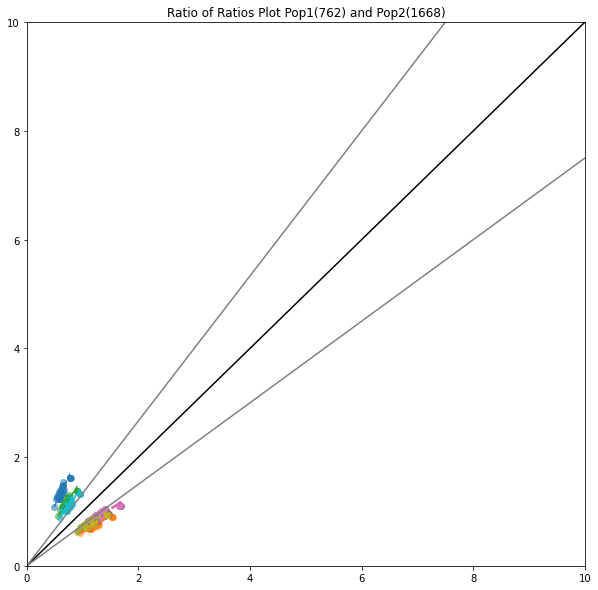

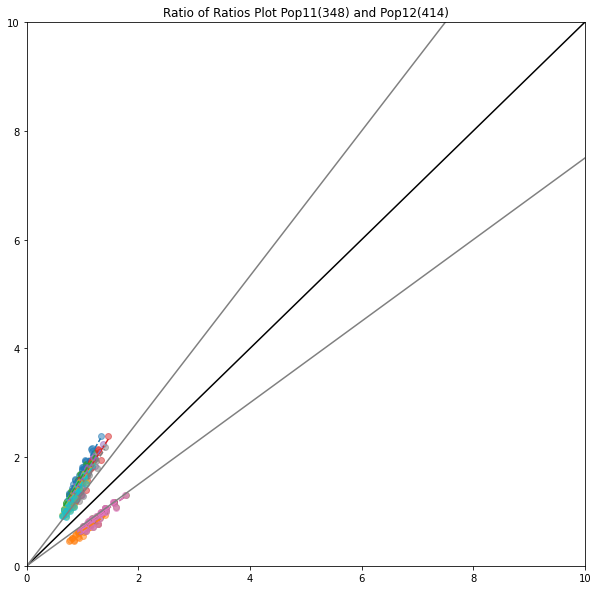

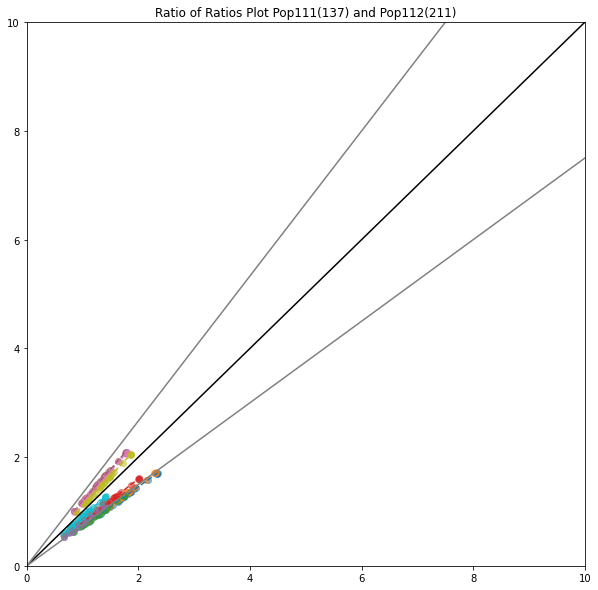

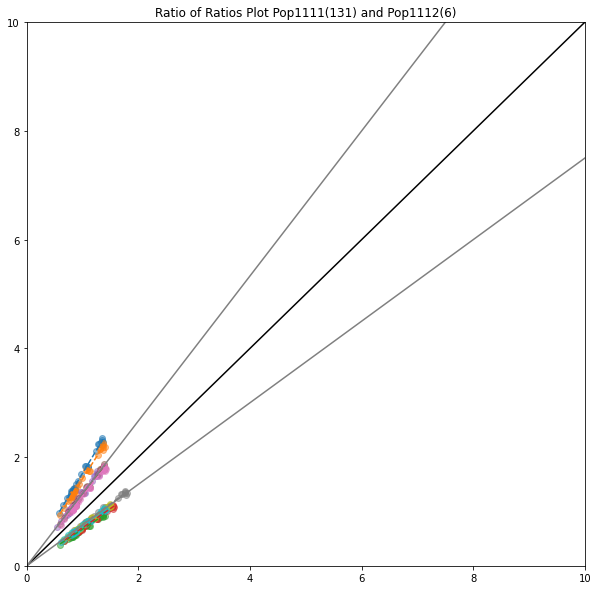

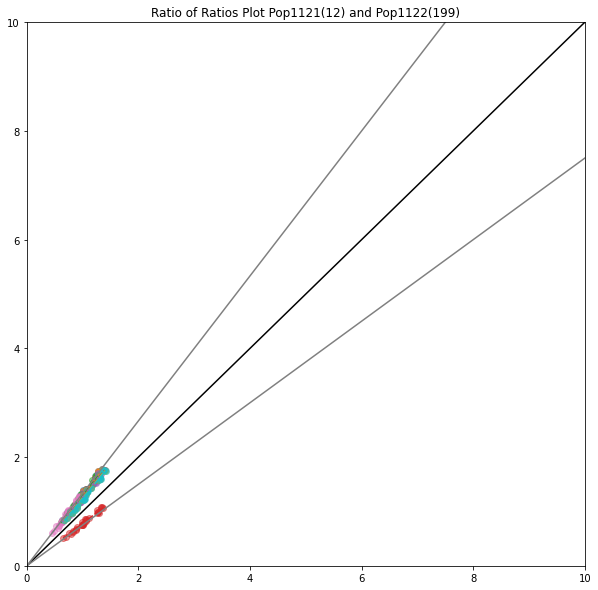

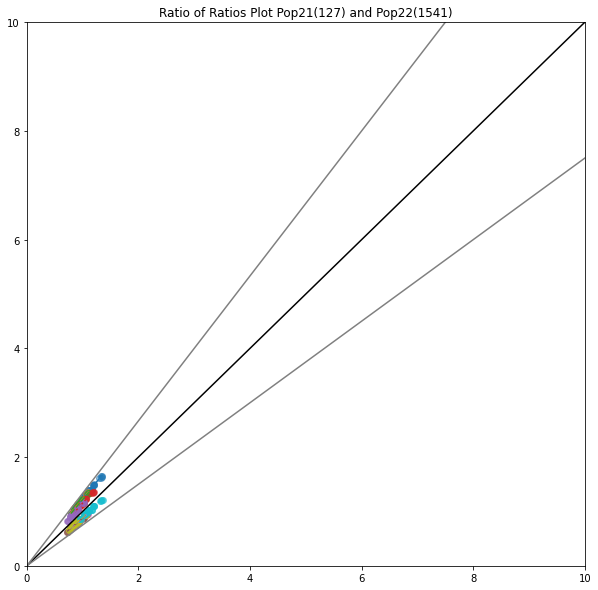

In [41]:
equi_bins_populations = recursive_em_split(all_data_no_WGS, cells, consensus_threshold=0.9, min_consensus=0.3, num_seeds=1, threshold=3/4, max_depth=10, name="Pop")

In [42]:
#stop

Processing population A with 2430 cells
Only one valid split found; accepting it.
Cluster 1: 761 cells
Cluster 2: 1669 cells
Unassigned (stragglers): 0 cells
Slopes for A: max=2.327, min=0.349
Split accepted for A: 761 + 1669 cells
  Processing population A1 with 761 cells
Only one valid split found; accepting it.
Cluster 1: 411 cells
Cluster 2: 350 cells
Unassigned (stragglers): 0 cells
  Slopes for A1: max=1.597, min=0.573
  Split accepted for A1: 411 + 350 cells
    Processing population A11 with 411 cells
Only one valid split found; accepting it.
Cluster 1: 88 cells
Cluster 2: 323 cells
Unassigned (stragglers): 0 cells
    Slopes for A11: max=1.378, min=0.656
    Split accepted for A11: 88 + 323 cells
      Processing population A111 with 88 cells
Only one valid split found; accepting it.
Cluster 1: 75 cells
Cluster 2: 13 cells
Unassigned (stragglers): 0 cells
      Slopes for A111: max=1.749, min=0.768
      Split produces too small subpopulations for A111
      Processing populat

/home/ranade/.local/lib/python3.6/site-packages/ipykernel_launcher.py:39: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`).


        Slopes for B2221: max=1.170, min=0.671
        Split accepted for B2221: 34 + 113 cells
          Processing population B22211 with 34 cells
          Population B22211 too small to split
          Processing population B22212 with 113 cells
Only one valid split found; accepting it.
Cluster 1: 90 cells
Cluster 2: 23 cells
Unassigned (stragglers): 0 cells
          Slopes for B22212: max=1.367, min=0.647
          Split produces too small subpopulations for B22212
        Processing population B2222 with 179 cells
Only one valid split found; accepting it.
Cluster 1: 153 cells
Cluster 2: 26 cells
Unassigned (stragglers): 0 cells
        Slopes for B2222: max=1.202, min=0.691
        Split accepted for B2222: 153 + 26 cells
          Processing population B22221 with 153 cells
Only one valid split found; accepting it.
Cluster 1: 45 cells
Cluster 2: 108 cells
Unassigned (stragglers): 0 cells
          Slopes for B22221: max=1.235, min=0.821
          Split rejected for B22221: slop

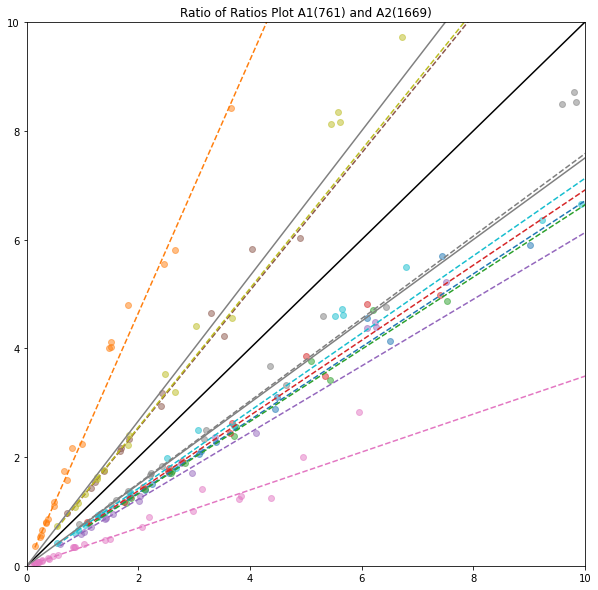

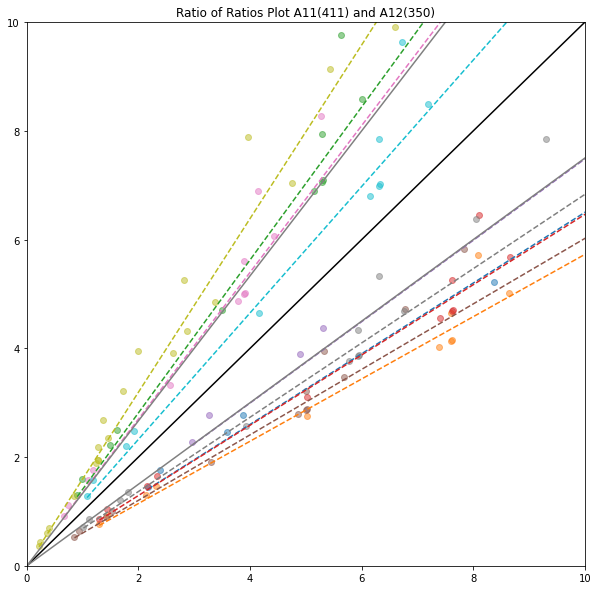

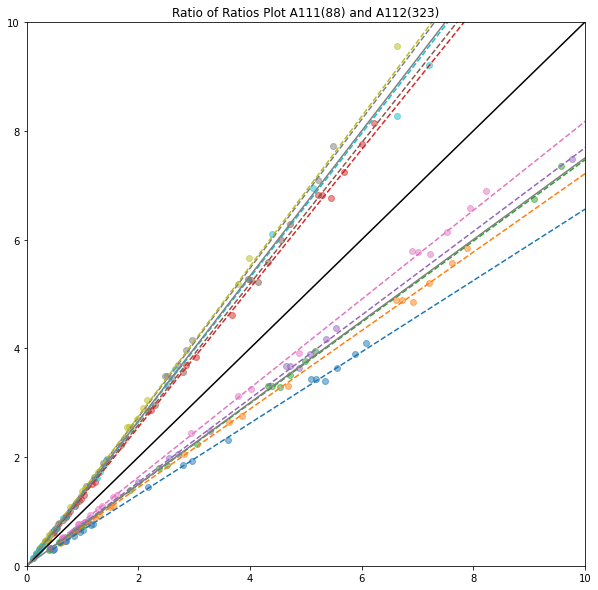

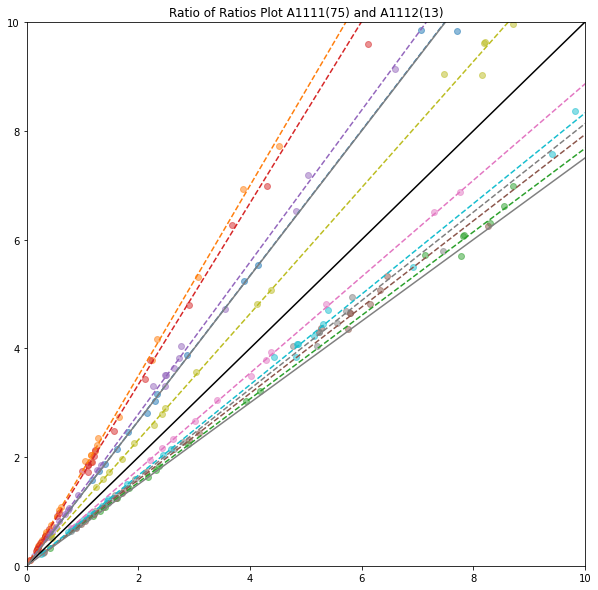

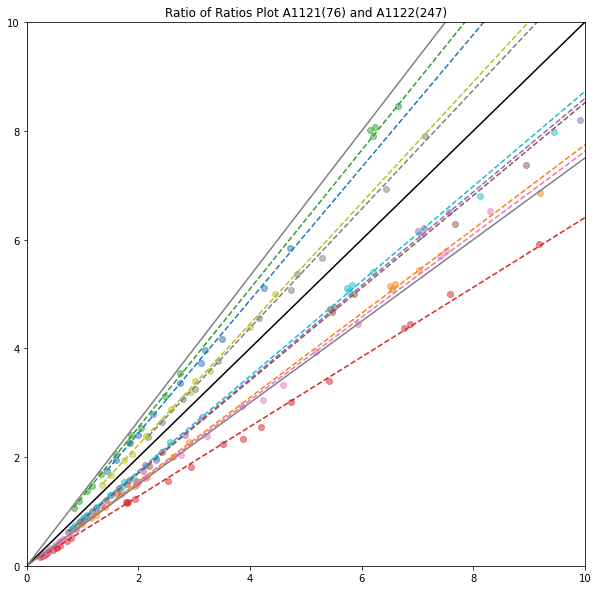

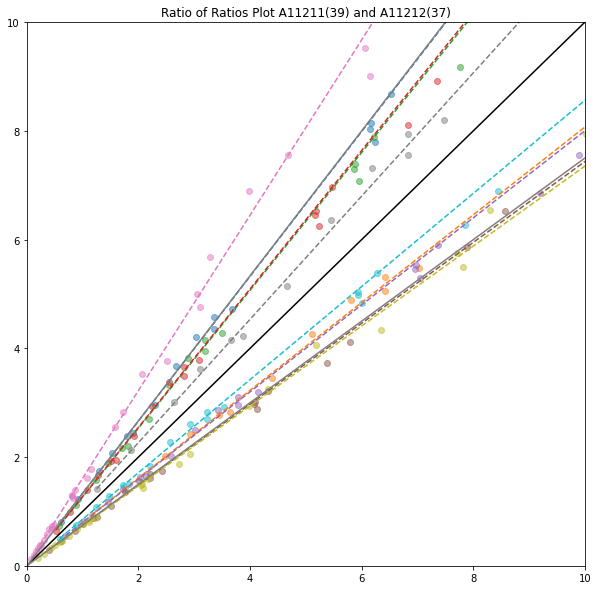

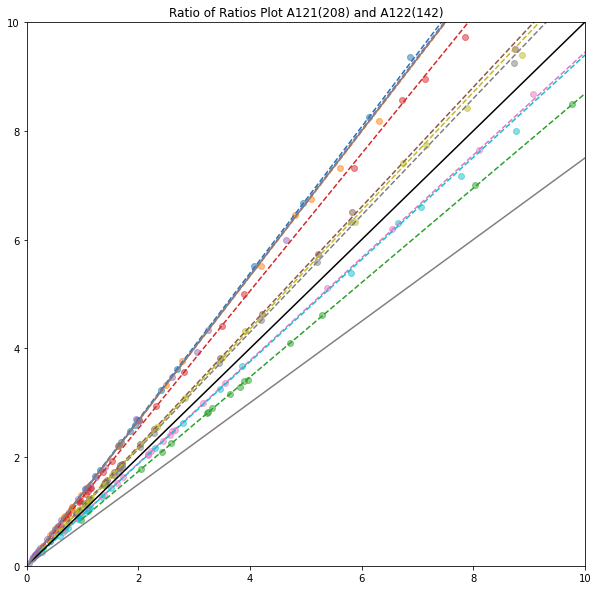

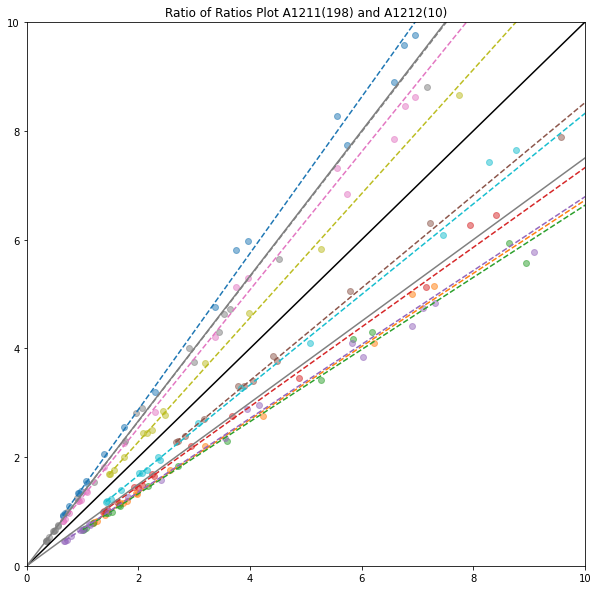

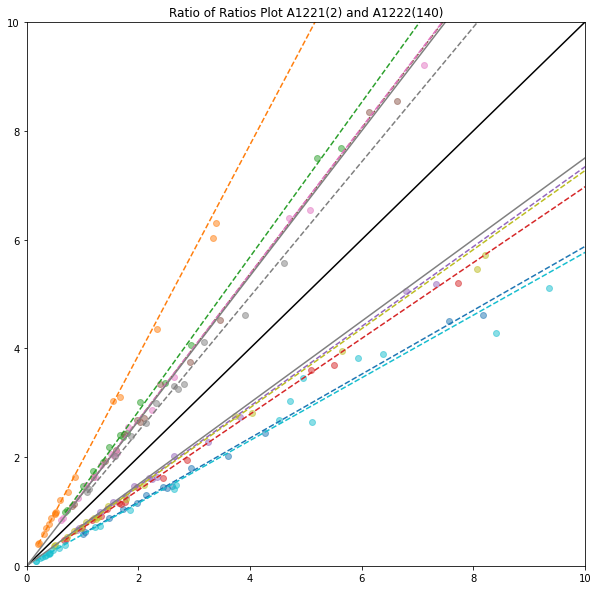

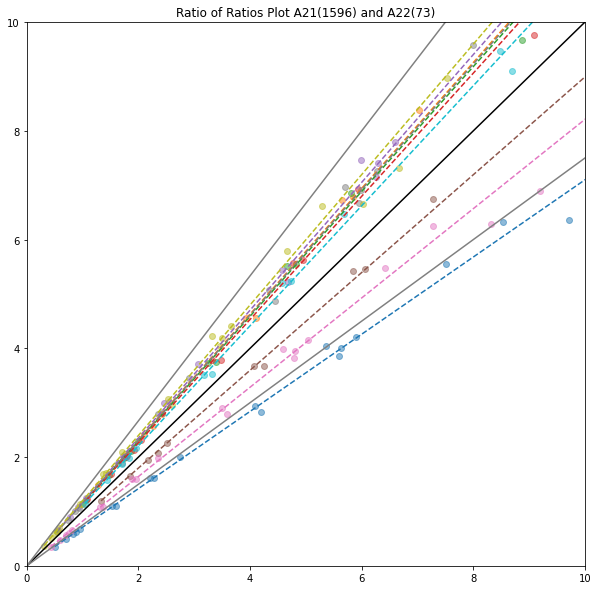

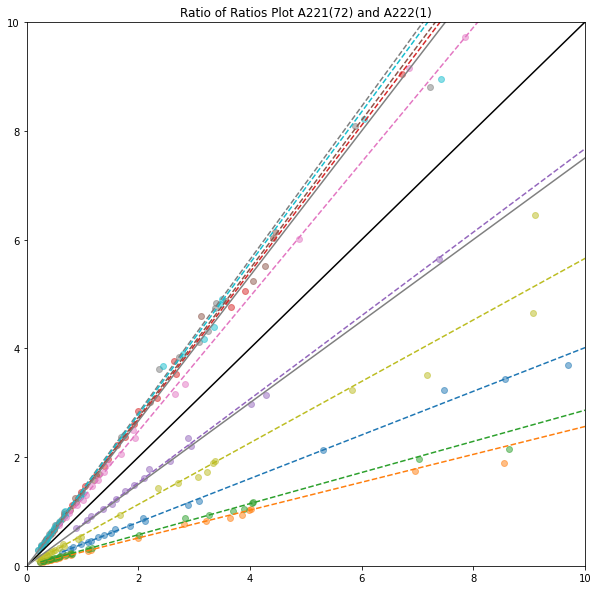

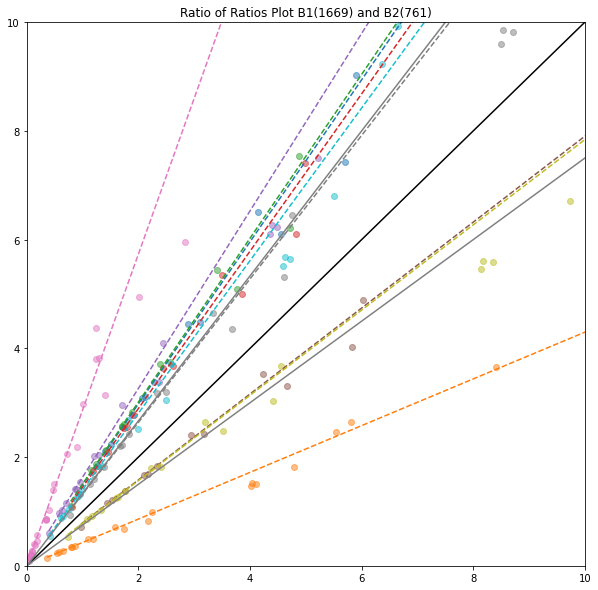

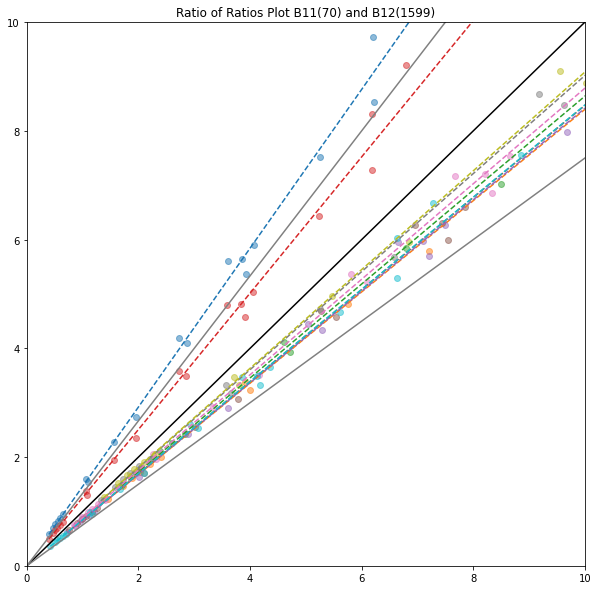

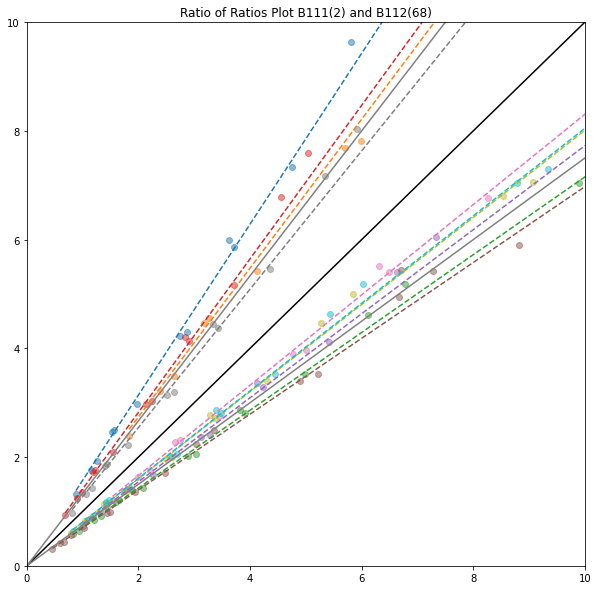

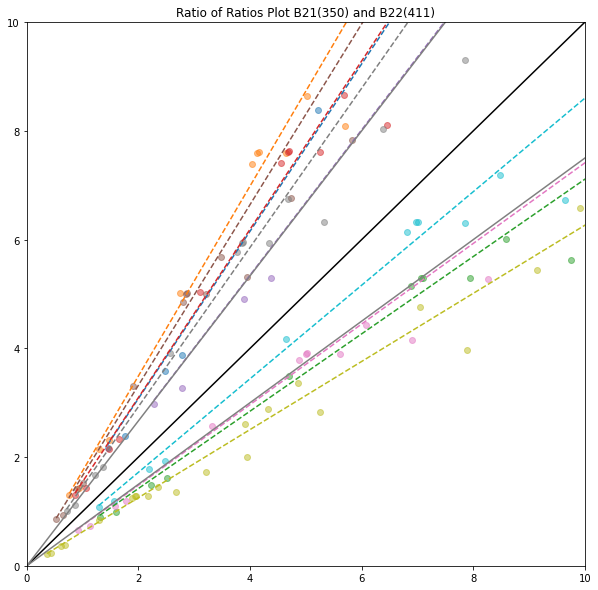

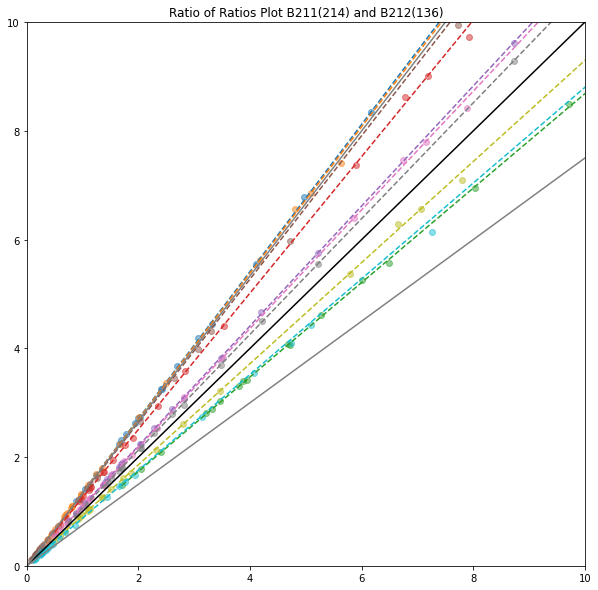

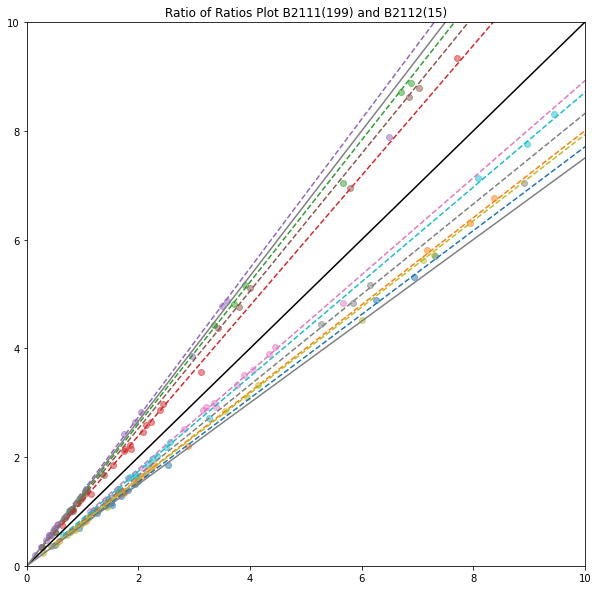

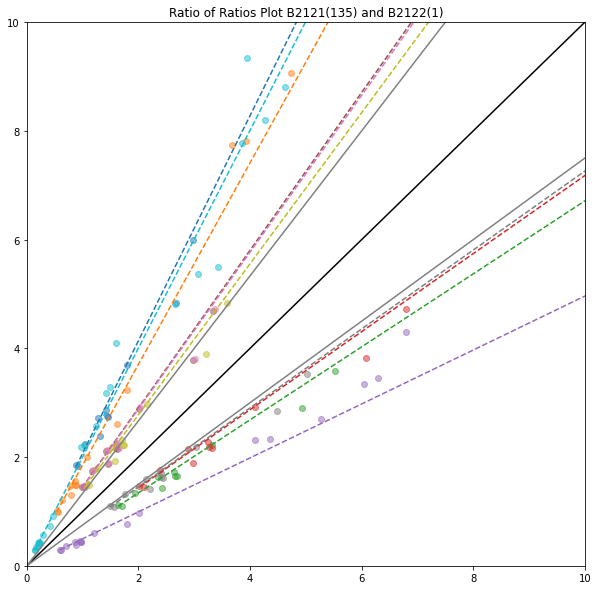

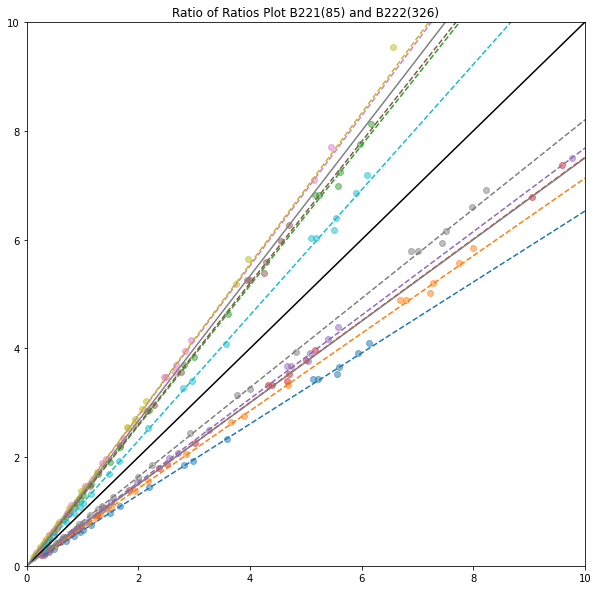

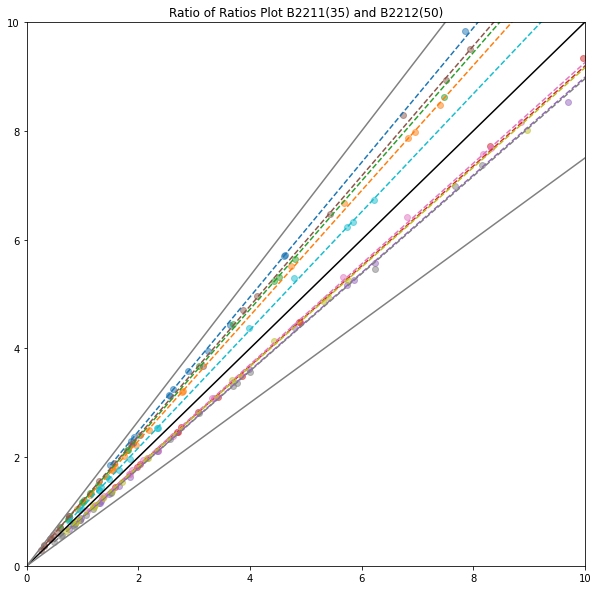

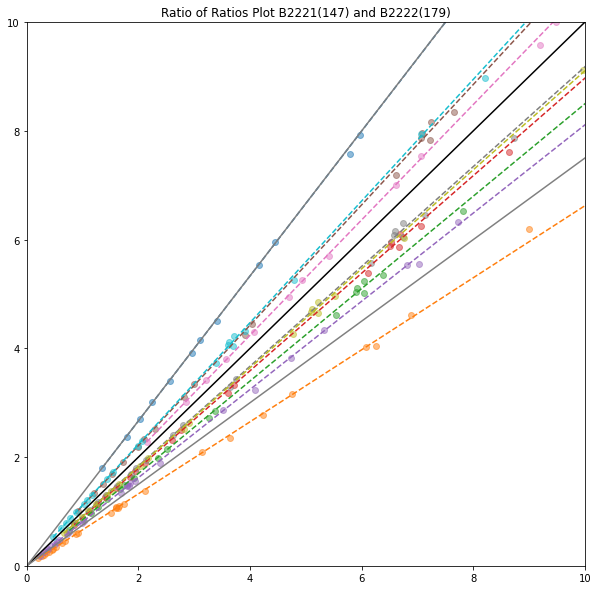

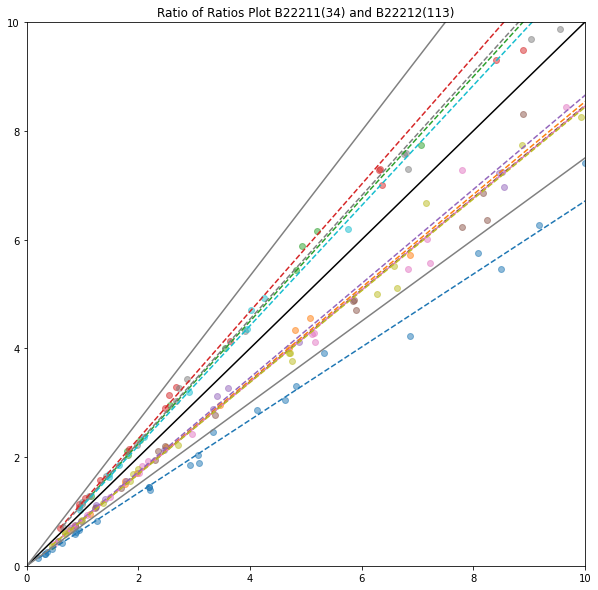

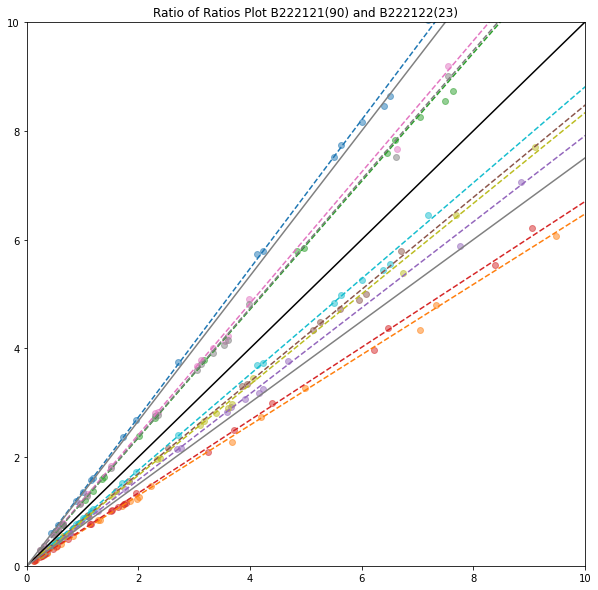

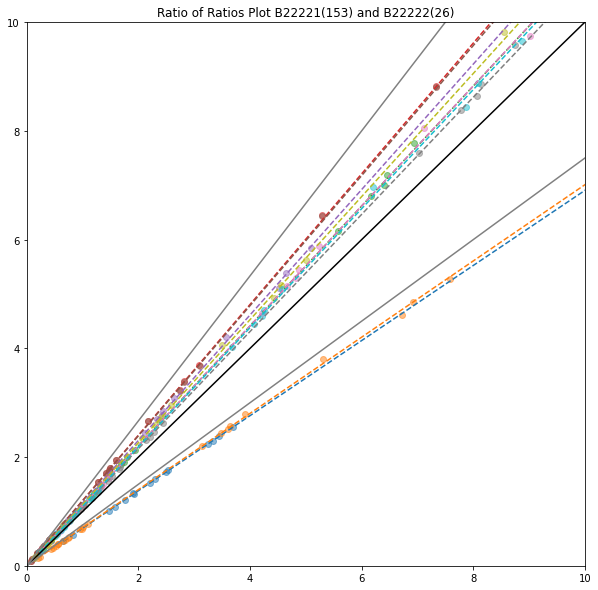

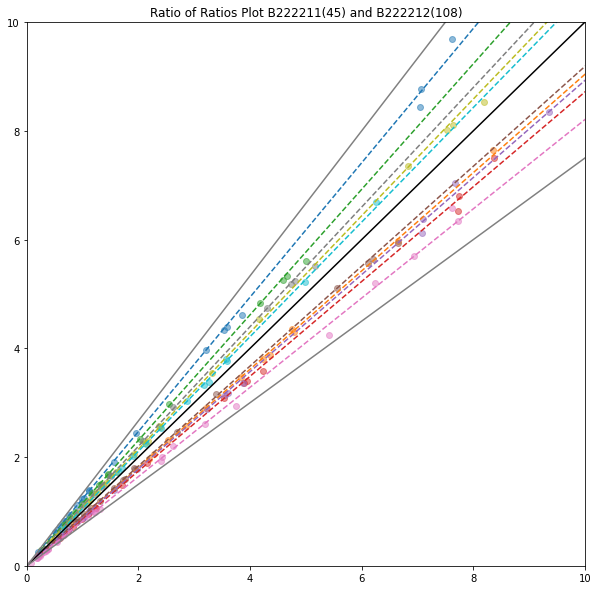

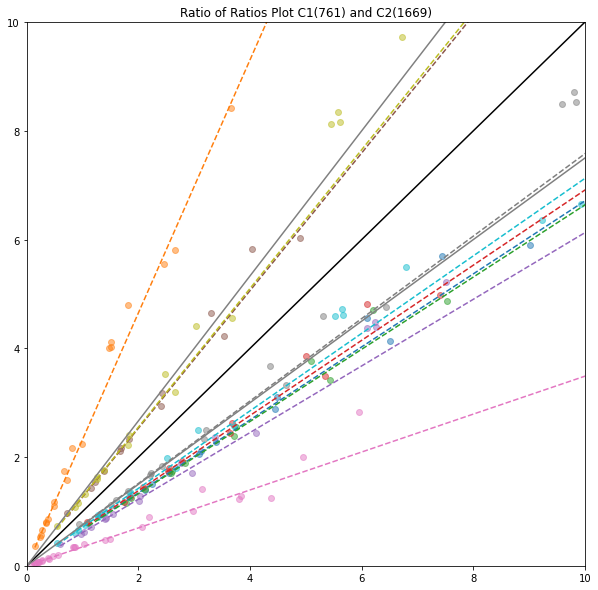

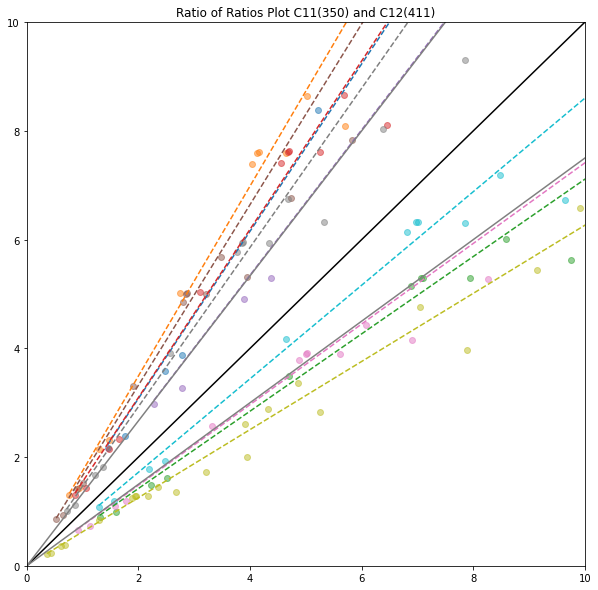

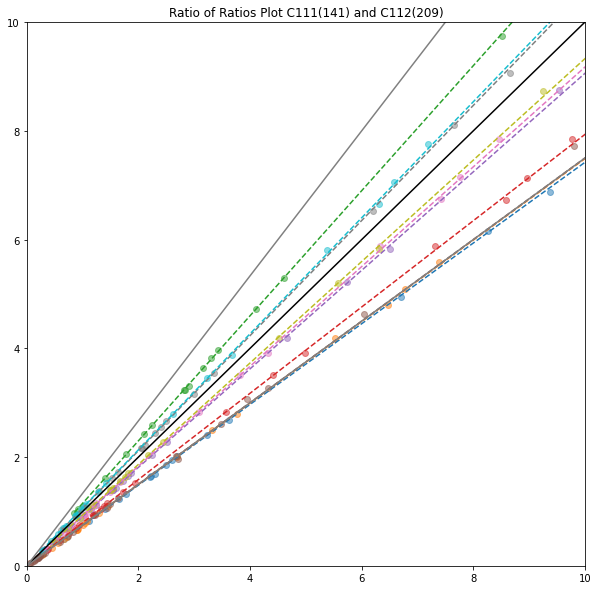

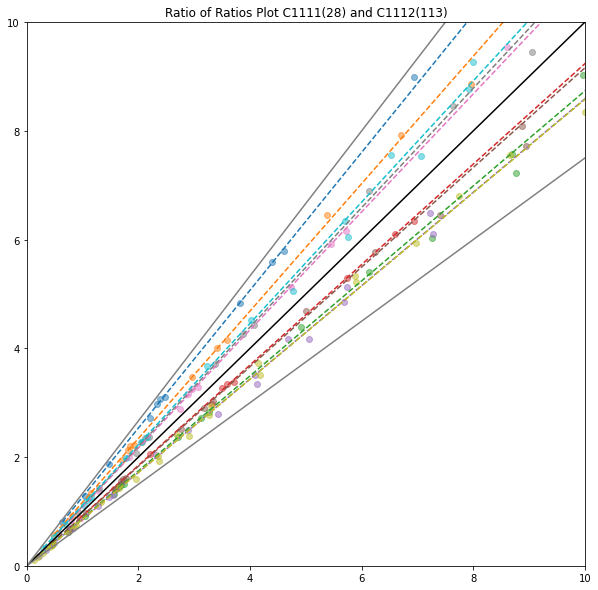

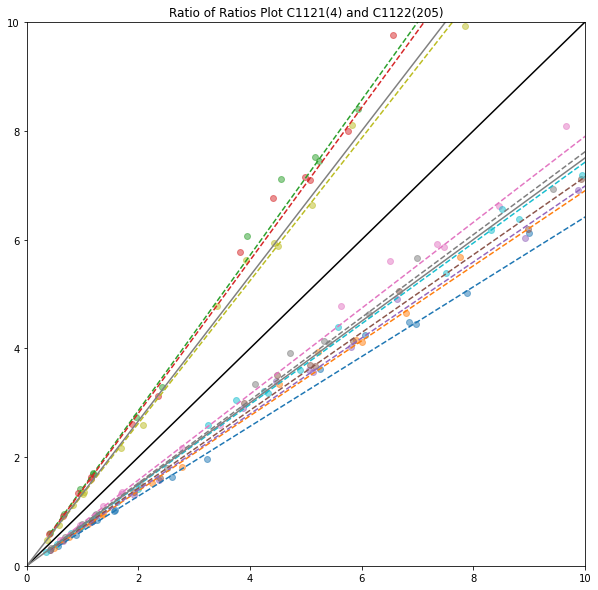

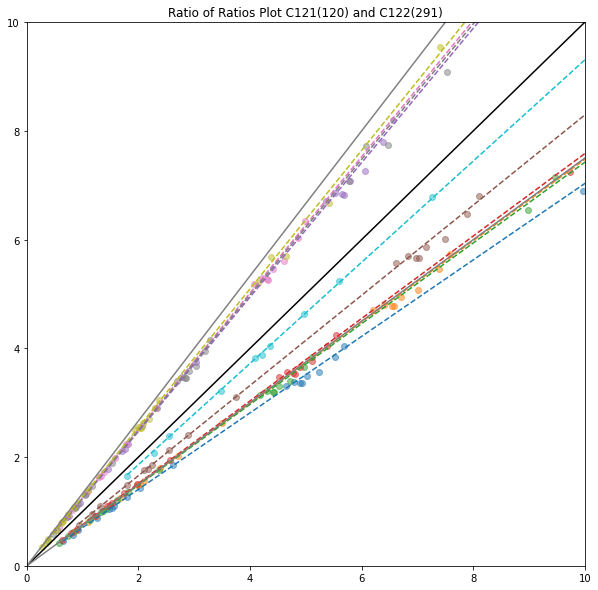

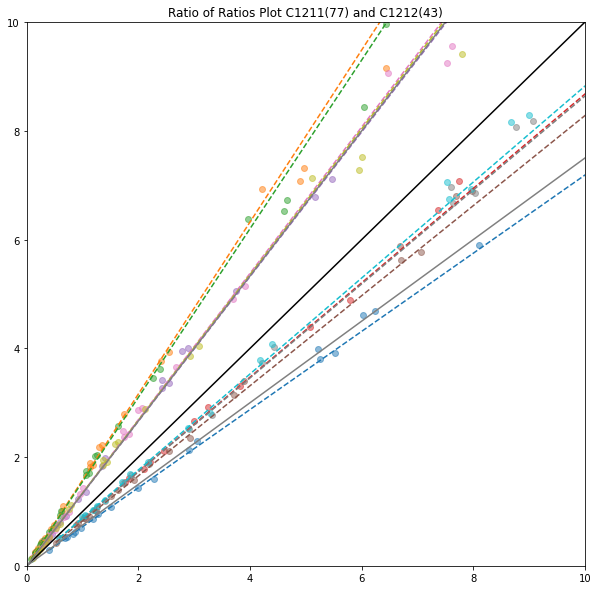

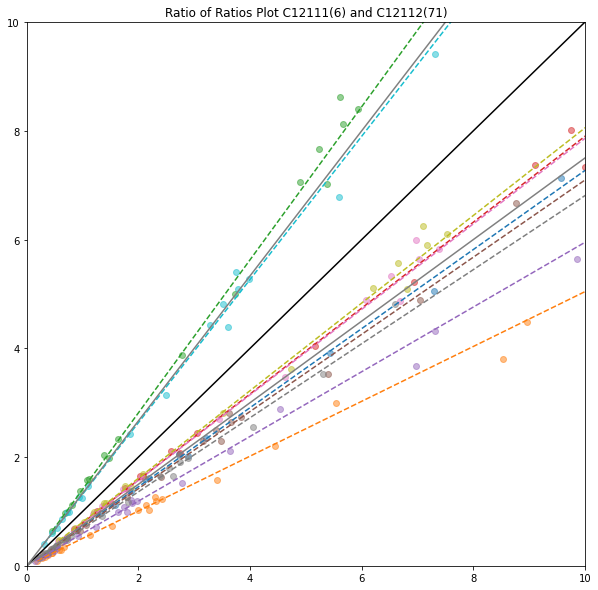

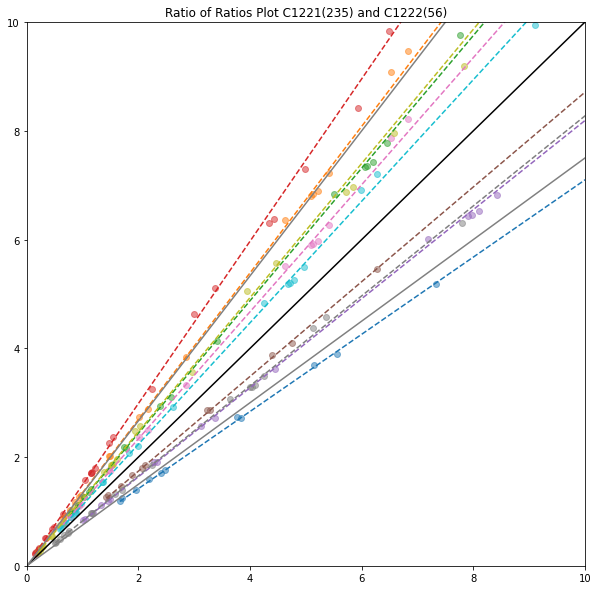

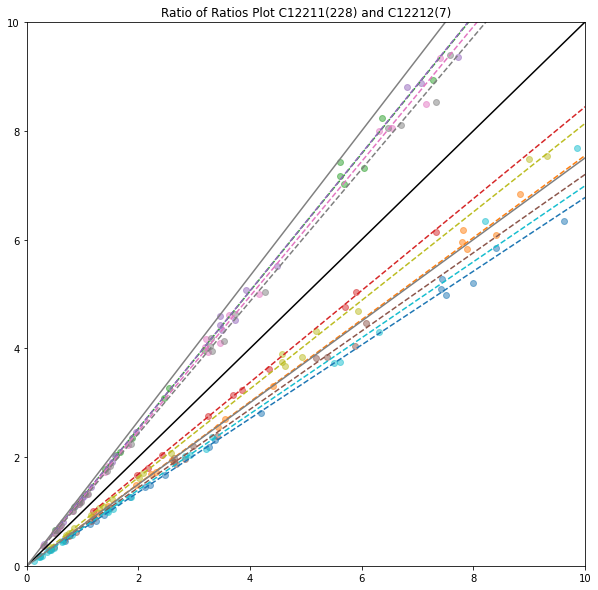

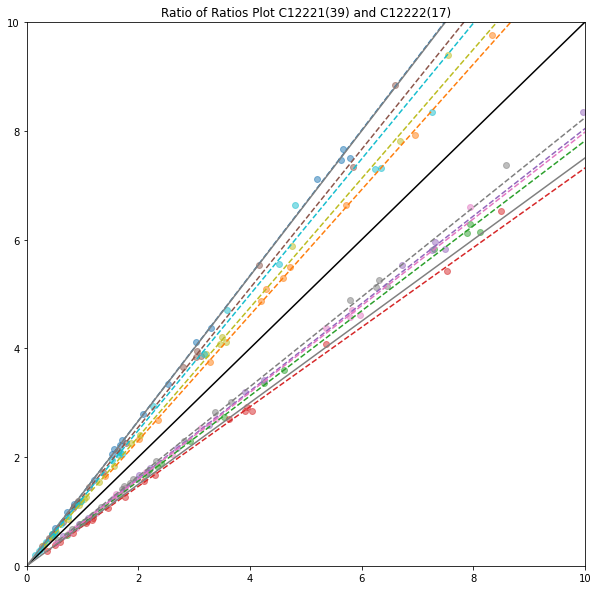

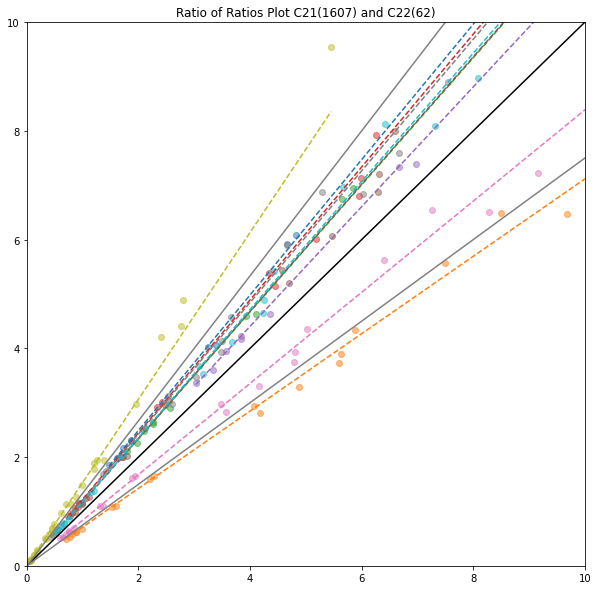

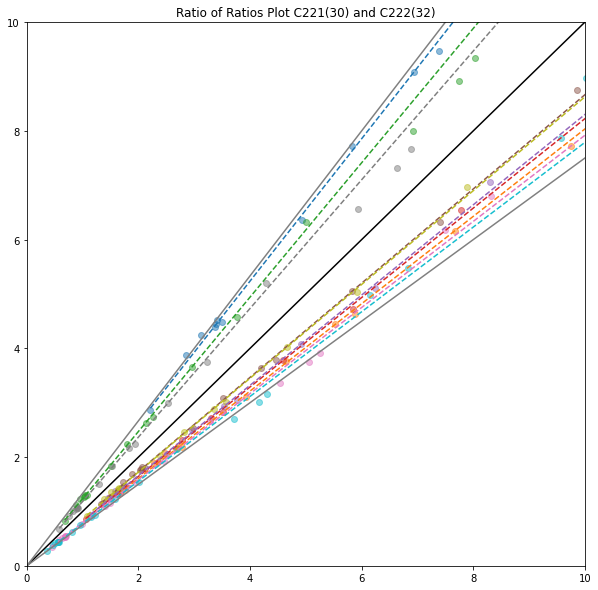

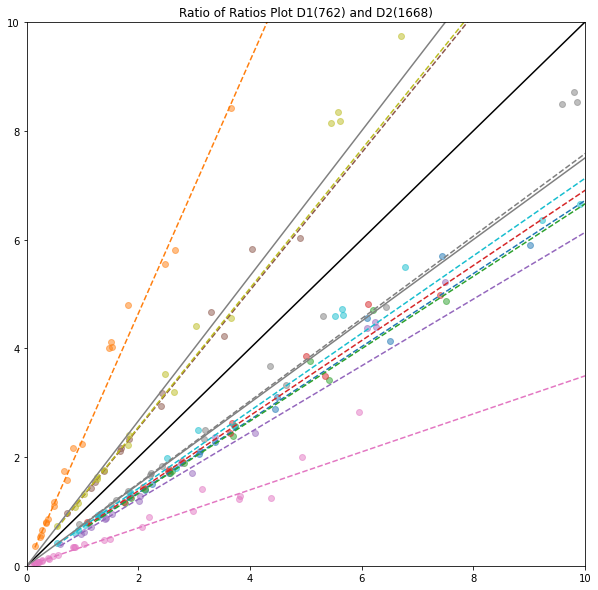

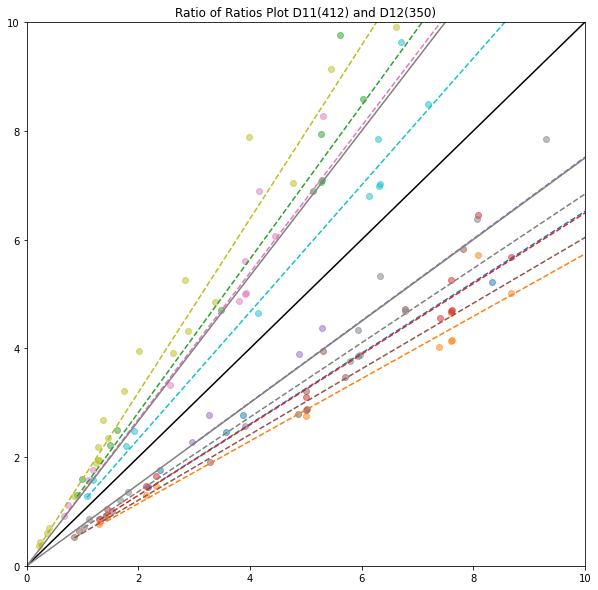

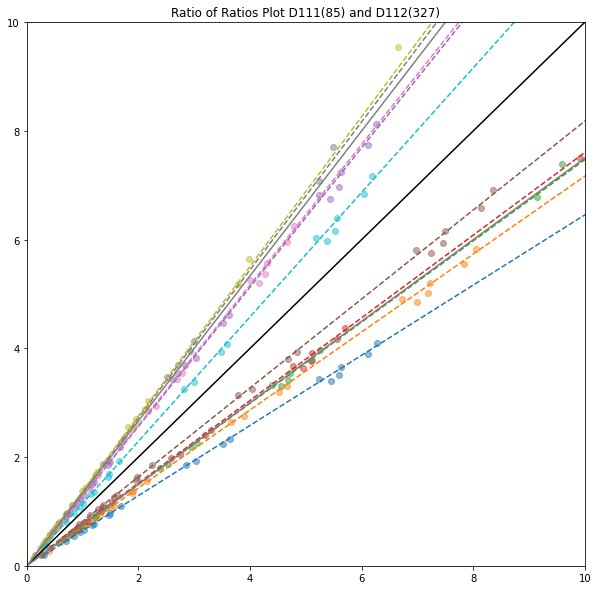

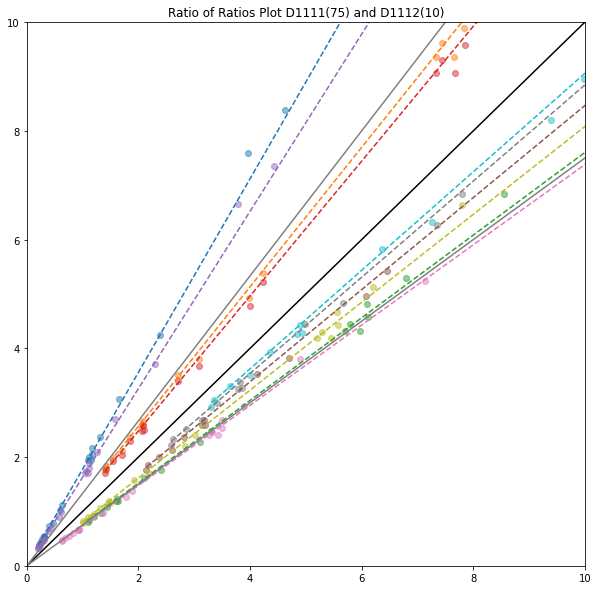

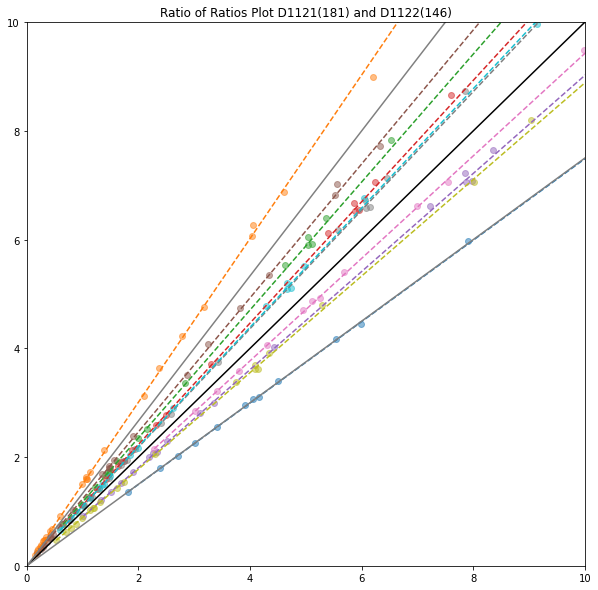

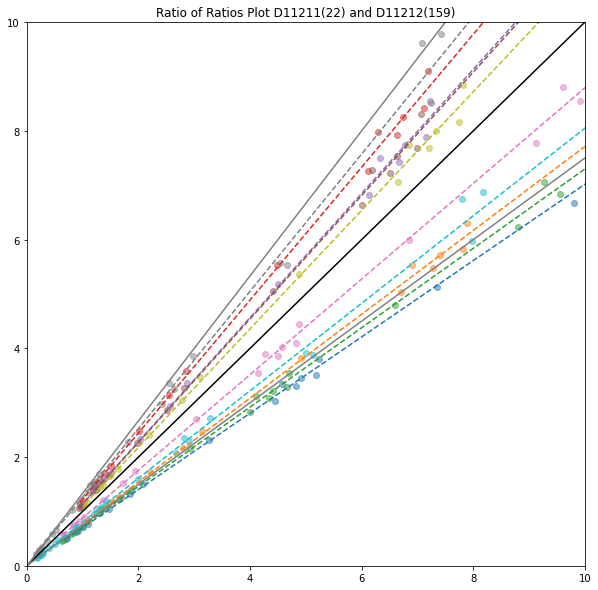

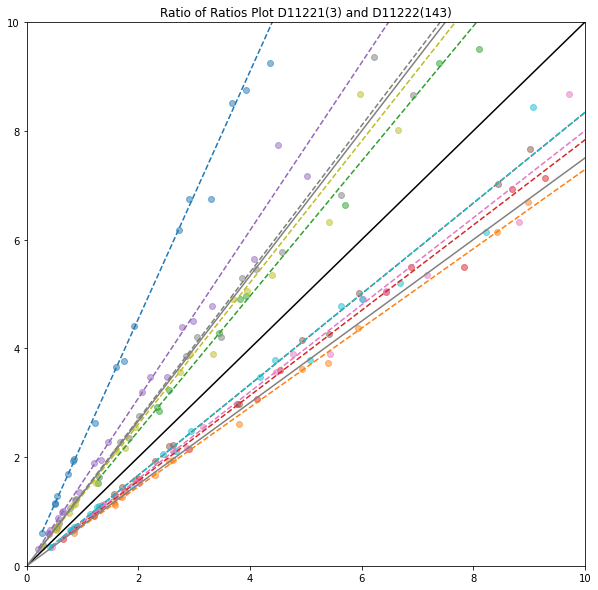

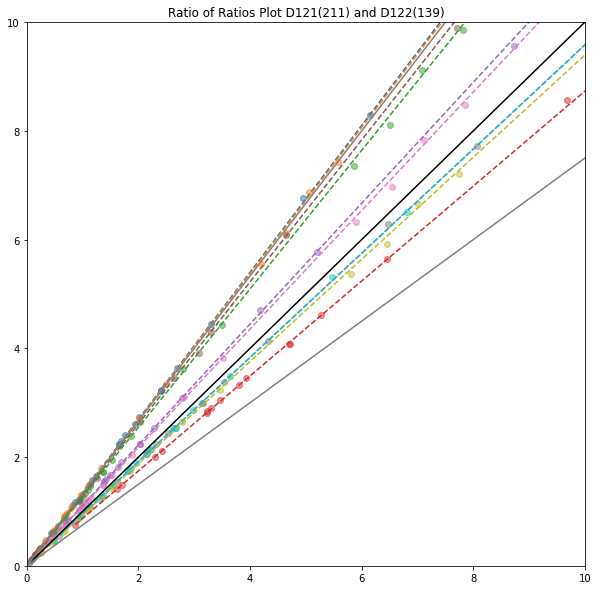

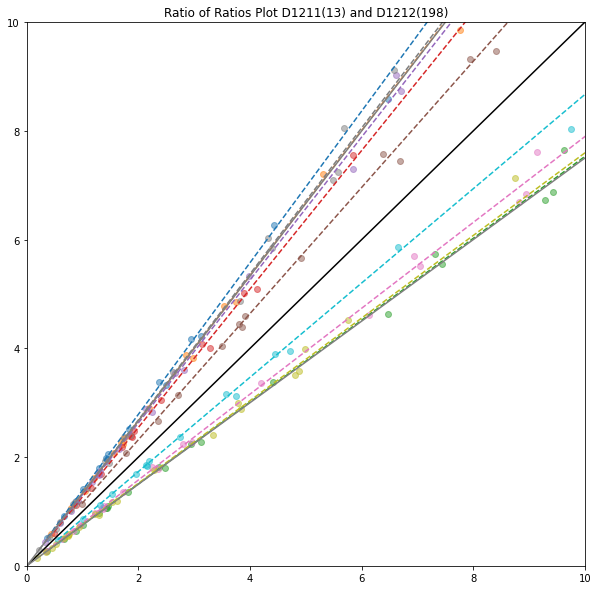

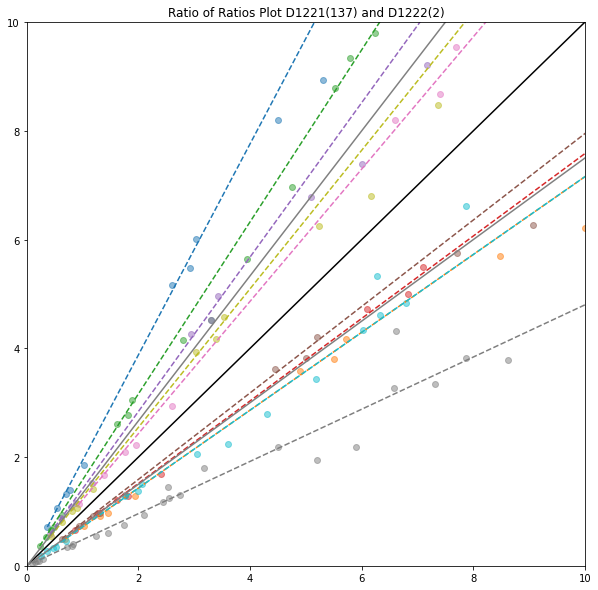

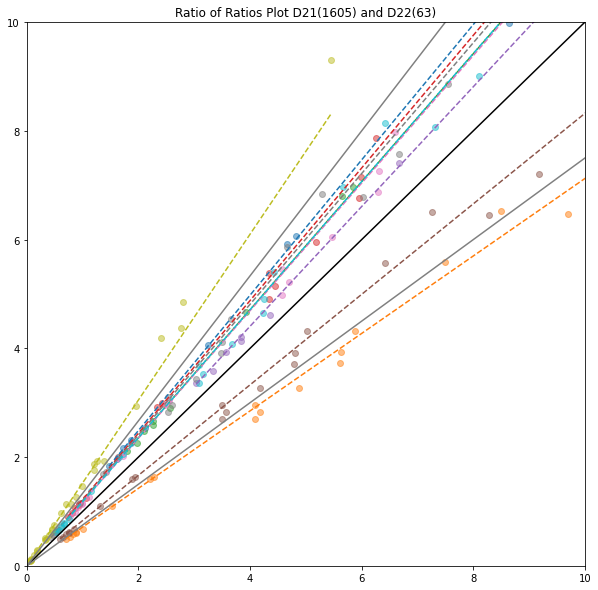

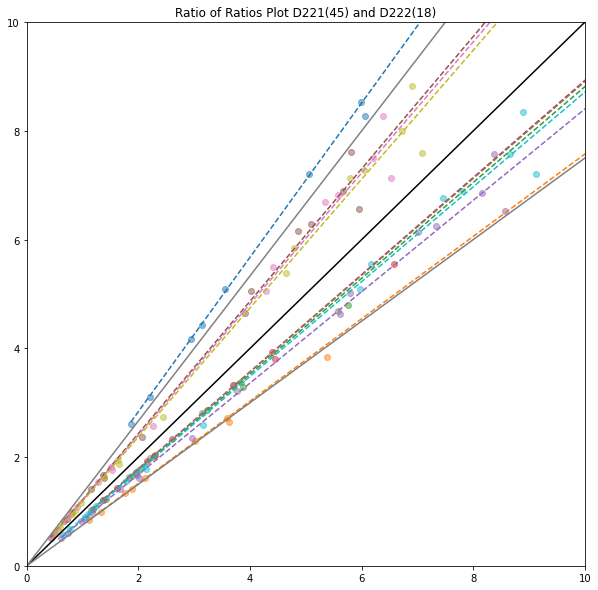

In [43]:
final_populations_A = recursive_em_split(
    all_data, cells, num_seeds=1,
    threshold=3/4, max_depth=10, name="A"
)

final_populations_B = recursive_em_split(
    all_data, cells, num_seeds=1,
    threshold=3/4, max_depth=10, name="B"
)

final_populations_C = recursive_em_split(
    all_data, cells, num_seeds=1,
    threshold=3/4, max_depth=10, name="C"
)

final_populations_D = recursive_em_split(
    all_data, cells, num_seeds=1,
    threshold=3/4, max_depth=10, name="D"
)

In [44]:
pop_no_WGS_dict = reassign_cells(all_data_no_WGS, equi_bins_populations)

In [45]:
A_dict = reassign_cells(all_data, final_populations_A)
B_dict = reassign_cells(all_data, final_populations_B)
C_dict = reassign_cells(all_data, final_populations_C)
D_dict = reassign_cells(all_data, final_populations_D)

In [46]:
A_dict.keys(), B_dict.keys()

(dict_keys(['A111', 'A11211', 'A11212', 'A1122', 'A121', 'A122', 'A21', 'A22']),
 dict_keys(['B11', 'B12', 'B211', 'B212', 'B221', 'B22211', 'B22212', 'B22221', 'B22222']))


Overlap Matrix (A rows vs B cols):
Pop          B11     B12    B211    B212    B221  B22211  B22212  B22221  B22222
A111           0       0       0       0      79       0       2       3       1
A11211         1       0       0       0       0      36       5       1       2
A11212         0       0       0       0       0       1      36       0       0
A1122          0       0       0       0       0       0      71     150      24
A121           1       0     207       0       0       0       0       0       0
A122           0       0       5     133       0       1       0       0       0
A21            4    1592       0       0       0       0       0       0       0
A22           63       7       1       0       0       4       0       0       0


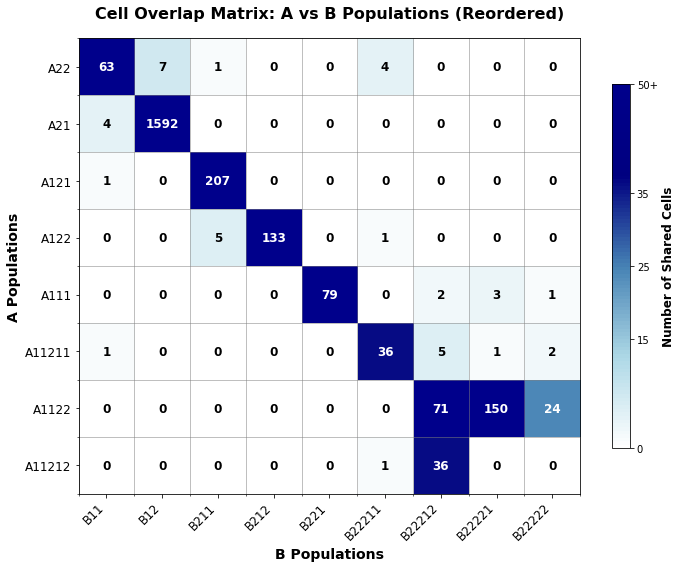

In [47]:
overlap_df = plot_overlap_matrix_figure(A_dict, B_dict, name1="A", name2="B")


Overlap Matrix (A rows vs B cols):
Pop         C111    C112   C1211   C1212   C1221   C1222     C21     C22
A111           0       0      76       8       0       1       0       0
A11211         0       0       0      35       0       9       0       1
A11212         0       0       0       1       0      36       0       0
A1122          0       0       0       6     233       6       0       0
A121           0     206       0       0       0       0       0       2
A122         138       0       0       0       0       0       0       1
A21            0       0       0       0       0       0    1594       2
A22            0       1       0       1       0       0      12      61


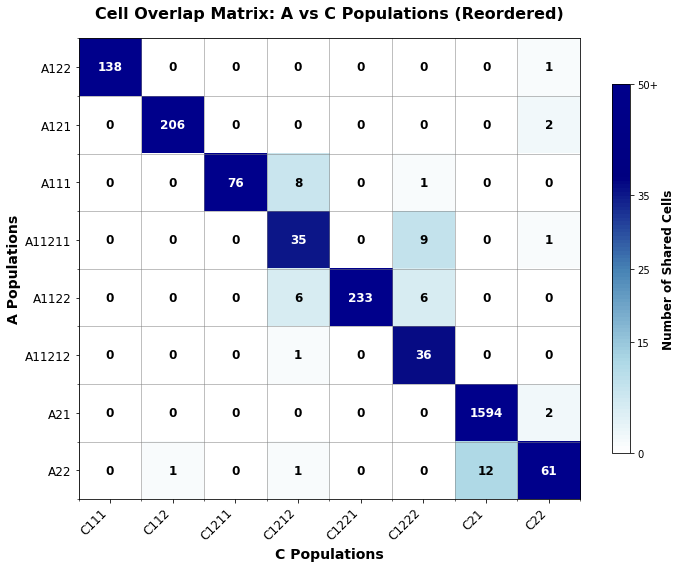

In [48]:
overlap_df = plot_overlap_matrix_figure(A_dict, C_dict, name1="A", name2="C")


Overlap Matrix (A rows vs B cols):
Pop         D111   D1121   D1122    D121    D122     D21     D22
A111          79       4       2       0       0       0       0
A11211         3       2      33       1       0       0       6
A11212         0       0      37       0       0       0       0
A1122          0     175      70       0       0       0       0
A121           0       0       0     206       1       0       1
A122           0       0       0       2     136       0       1
A21            0       0       0       0       0    1593       3
A22            0       0       0       1       0      12      62


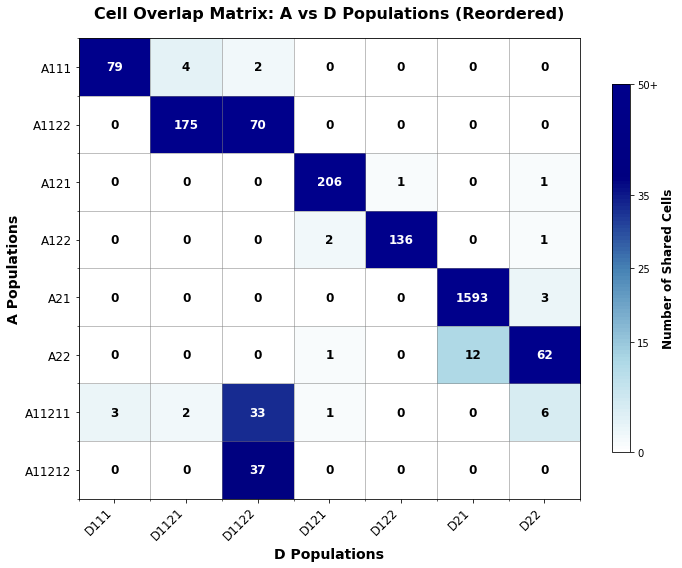

In [49]:
overlap_df = plot_overlap_matrix_figure(A_dict, D_dict, name1="A", name2="D")


Overlap Matrix (A rows vs B cols):
Pop         C111    C112   C1211   C1212   C1221   C1222     C21     C22
B11            0       0       0       0       0       0       8      61
B12            0       0       0       0       0       0    1598       1
B211           5     207       0       0       0       0       0       1
B212         133       0       0       0       0       0       0       0
B221           0       0      75       4       0       0       0       0
B22211         0       0       0      31       0       7       0       4
B22212         0       0       1       4      64      45       0       0
B22221         0       0       0       9     145       0       0       0
B22222         0       0       0       3      24       0       0       0


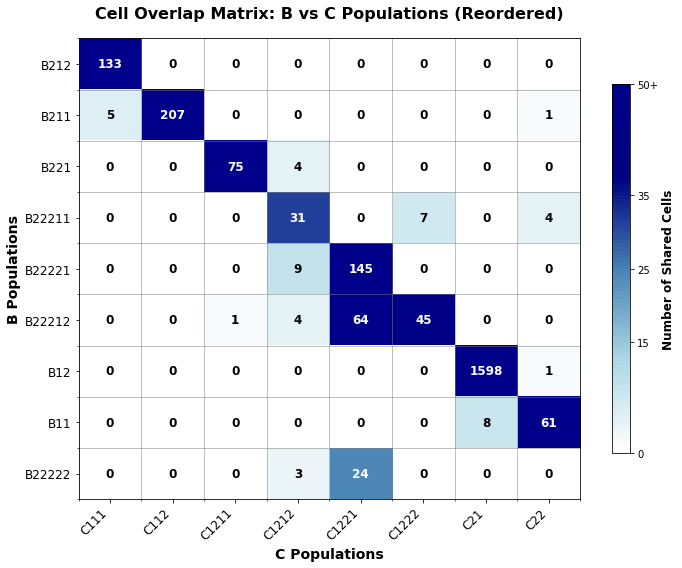

In [50]:
overlap_df = plot_overlap_matrix_figure(B_dict, C_dict, name1="B", name2="C")


Overlap Matrix (A rows vs B cols):
Pop         D111   D1121   D1122    D121    D122     D21     D22
B11            0       0       0       0       0       7      62
B12            0       0       0       0       0    1598       1
B211           0       0       0     209       4       0       0
B212           0       0       0       0     133       0       0
B221          79       0       0       0       0       0       0
B22211         3       0      28       1       0       0      10
B22212         0       3     111       0       0       0       0
B22221         0     151       3       0       0       0       0
B22222         0      27       0       0       0       0       0


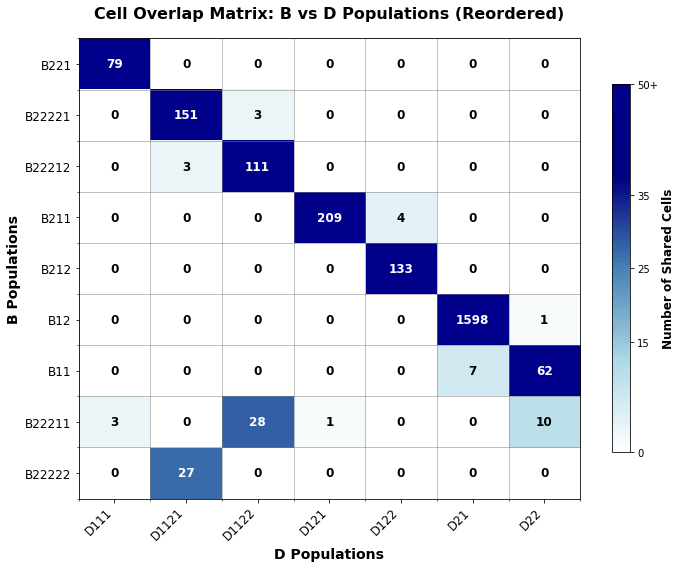

In [51]:
overlap_df = plot_overlap_matrix_figure(B_dict, D_dict, name1="B", name2="D")


Overlap Matrix (A rows vs B cols):
Pop         C111    C112   C1211   C1212   C1221   C1222     C21     C22
D111           0       0      75       7       0       0       0       0
D1121          0       0       0      11     170       0       0       0
D1122          0       0       1      26      63      52       0       0
D121           2     206       0       1       0       0       0       1
D122         136       1       0       0       0       0       0       0
D21            0       0       0       0       0       0    1604       1
D22            0       0       0       6       0       0       2      65


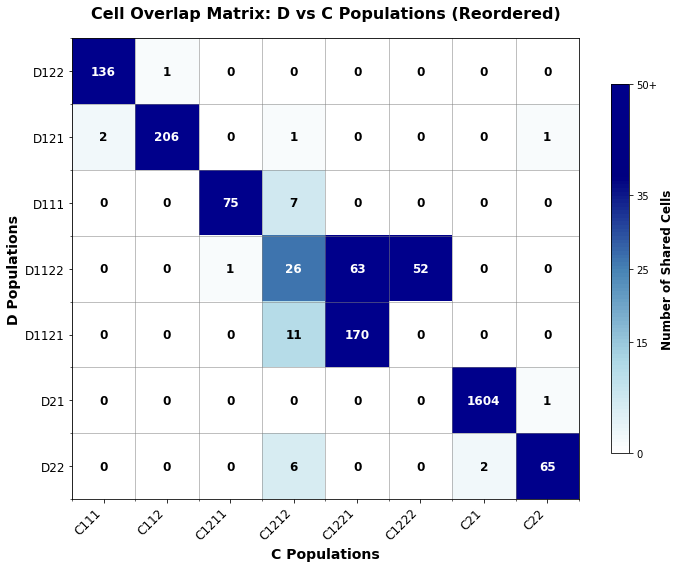

In [52]:
overlap_df = plot_overlap_matrix_figure(D_dict, C_dict, name1="D", name2="C")

In [53]:
#stop

In [54]:
all_data

,AAAACCAACCTGATAAC,AAAACCAACTTTTGACG,AAAACCAATTTCAGTAC,AAAACCACTGGCCTTAC,AAAACCAGCTTAGATAC,AAAACCAGTGAGTCTAC,AAAACCATGAGGAGAAG,AAAACCGAAATCGGTAT,AAAACCGAACCCGTACA,AAAACCGGACGTATTAA,...,TTTTGGACATGAAGTCG,TTTTGGAGTGAGAGTCG,TTTTGGATTCCTTCTCG,TTTTGGCTTGGCTCAAG,TTTTGGGAAATCCGTGA,TTTTGGGACCATGTACA,TTTTGGGACGAAGTAGC,TTTTGGGTGCAATGTCC,TTTTGGTATTCTAGTAC,TTTTGGTTTGGAAGTAC
0,570,1604,403,1325,853,310,866,479,1113,1009,...,1193,800,798,1995,971,1103,884,903,1125,834
1,928,5401,596,4437,2675,449,1412,1646,1941,3164,...,4002,1326,2425,4022,1563,1792,2275,3026,3954,1429
2,506,2172,294,1671,1987,253,769,649,974,1250,...,3050,879,995,3032,789,896,1354,2382,1533,669
3,83,230,66,184,232,53,139,59,162,200,...,384,147,152,384,133,136,159,244,283,132
4,819,2760,612,1954,1335,462,1276,696,1681,1404,...,1963,1517,1092,2582,1421,1596,1217,1684,1892,1228
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
84,77,203,57,136,97,52,91,60,139,116,...,125,121,98,230,123,185,79,137,188,115
85,284,1063,185,814,340,140,391,258,468,570,...,775,365,518,939,413,513,355,656,902,367
86,770,2422,427,2247,1576,367,1134,935,1401,2336,...,1683,1672,1823,3073,1077,1260,1210,1777,2316,1013
87,419,1614,238,1326,1198,222,615,504,808,1035,...,1636,906,815,2043,611,762,861,1475,969,560


In [55]:

# # Assumes all_data is already defined and ready to use
# # e.g. all_data = data[cells].copy()

# n_reps = 100
# rng = np.random.default_rng(12345)

# # ---------------------------------------------------------------------
# # 1) Run EM 100 times on the real data and keep each run's mult_KV + log-lik
# # ---------------------------------------------------------------------
# real_results = {
#     "log_lik": [],
#     "mult_KV": []
# }

# q_data = all_data / all_data.sum(axis=0)

# for i in range(n_reps):
#     print(f"Running EM on real data, iteration {i+1}/{n_reps}")
#     s = make_random_seeds(q_data, num_seeds=1)[0]
#     logprob_NK, log_lik, mult_KV = EM_algorithm(all_data, s)
#     if np.isfinite(log_lik):
#         real_results["log_lik"].append(float(log_lik))
#         real_results["mult_KV"].append(np.asarray(mult_KV, dtype=float))

# real_results["log_lik"] = np.asarray(real_results["log_lik"])
# real_results["mult_KV"] = np.asarray(real_results["mult_KV"])

# print("EM run on real data completed")

# # # ---------------------------------------------------------------------
# # # 2) Consensus split on the real data using the existing function
# # # ---------------------------------------------------------------------
# # cells_1, cells_2, unassigned, consensus_mult_KV = consensus_split_population(
# #     all_data,
# #     consensus_threshold=0.9,
# #     min_consensus=0.3,
# #     num_seeds=100,
# # )



In [56]:
# # ---------------------------------------------------------------------
# # 3) Simulate random data with the same number of cells as all_data, 100 times
# #    and run EM once per simulation
# # ---------------------------------------------------------------------
# real_cell_totals = all_data.sum(axis=0).to_numpy()
# global_probs = all_data.sum(axis=1).to_numpy() / all_data.to_numpy().sum()

# n_cells = all_data.shape[1]

# random_results = {
#     "log_lik": [],
#     "mult_KV": []
# }

# for rep in range(n_reps):
#     print(f"Running EM on random data, iteration {rep+1}/{n_reps}")
#     # Sample total count for each simulated cell from the real-cell total-count distribution
#     sim_cell_totals = rng.choice(real_cell_totals, size=n_cells, replace=True)

#     # Build one random cell at a time from a multinomial using the global distribution
#     sim_matrix = np.column_stack([
#         rng.multinomial(int(total_count), global_probs)
#         for total_count in sim_cell_totals
#     ])

#     sim_data = pd.DataFrame(
#         sim_matrix,
#         index=all_data.index,
#         columns=all_data.columns
#     )

#     # Run EM once on this simulated dataset
#     q_sim = sim_data / sim_data.sum(axis=0)
#     s = make_random_seeds(q_sim, num_seeds=1)[0]
#     logprob_NK, log_lik, mult_KV = EM_algorithm(sim_data, s)
#     print(f"Log-likelihood for this random dataset: {log_lik}")
#     #print(f"Multinomial parameters for this random dataset:\n{mult_KV}")

#     if np.isfinite(log_lik):
#         random_results["log_lik"].append(float(log_lik))
#         random_results["mult_KV"].append(np.asarray(mult_KV, dtype=float))

# random_results["log_lik"] = np.asarray(random_results["log_lik"])
# random_results["mult_KV"] = np.asarray(random_results["mult_KV"])
# print("EM run on random data completed")




In [57]:
# plt.scatter(range(len(real_results["log_lik"])), sorted(real_results["log_lik"]), label="Real Data", alpha=0.7)
# plt.scatter(range(len(random_results["log_lik"])), sorted(random_results["log_lik"]), label="Random Data", alpha=0.7)
# #plt.xlabel("Iteration")
# plt.ylabel("Log-Likelihood")
# plt.legend()
# plt.show()

In [58]:
# # ---------------------------------------------------------------------
# # Real data: run EM on 100 random seeds and save each valid log-likelihood
# # ---------------------------------------------------------------------
# q_data = all_data / all_data.sum(axis=0)

# real_results = {
#     "log_lik": [],
#     "mult_KV": []
# }
# count = 1
# for s in make_random_seeds(q_data, num_seeds=100):
#     print(f"Running EM on real data, seed {count}/100")
#     count += 1
#     logprob_NK, log_lik, mult_KV = EM_algorithm(all_data, s)
#     if np.isfinite(log_lik):
#         real_results["log_lik"].append(float(log_lik))
#         real_results["mult_KV"].append(np.asarray(mult_KV, dtype=float))

# real_results["log_lik"] = np.asarray(real_results["log_lik"])
# real_results["mult_KV"] = np.asarray(real_results["mult_KV"])

# print("Real-data runs kept:", len(real_results["log_lik"]))
# print("Real-data median log-likelihood:", np.median(real_results["log_lik"]))
# print("Real-data max log-likelihood:", np.max(real_results["log_lik"]))

# # ---------------------------------------------------------------------
# # Random null: simulate 100 datasets, run EM once per dataset, save each valid result
# # ---------------------------------------------------------------------
# rng = np.random.default_rng(12345)

# real_cell_totals = all_data.sum(axis=0).to_numpy()
# global_probs = all_data.sum(axis=1).to_numpy() / all_data.to_numpy().sum()
# n_cells = all_data.shape[1]

# random_results = {
#     "log_lik": [],
#     "mult_KV": []
# }

# for rep in range(100):
#     print(f"Running EM on random dataset, iteration {rep+1}/100")
#     sim_cell_totals = rng.choice(real_cell_totals, size=n_cells, replace=True)

#     sim_matrix = np.column_stack([
#         rng.multinomial(int(total_count), global_probs)
#         for total_count in sim_cell_totals
#     ])

#     sim_data = pd.DataFrame(sim_matrix, index=all_data.index, columns=all_data.columns)

#     q_sim = sim_data / sim_data.sum(axis=0)
#     s = make_random_seeds(q_sim, num_seeds=1)[0]

#     logprob_NK, log_lik, mult_KV = EM_algorithm(sim_data, s)
#     if np.isfinite(log_lik):
#         random_results["log_lik"].append(float(log_lik))
#     random_results["mult_KV"].append(np.asarray(mult_KV, dtype=float))

# random_results["log_lik"] = np.asarray(random_results["log_lik"])
# random_results["mult_KV"] = np.asarray(random_results["mult_KV"])

# print("Random-data runs kept:", len(random_results["log_lik"]))
# print("Random-data median log-likelihood:", np.median(random_results["log_lik"]))
# print("Random-data max log-likelihood:", np.max(random_results["log_lik"]))

In [59]:
def EM_algorithm_test(data, s, Min_Diff=0.001, Max_Iter=15):
    obs_NV = np.array(data).T
    log_likelihood = -np.inf

    mult_KV = np.array(s).T
    mult_KV = mult_KV / np.sum(mult_KV, axis=1)[:, np.newaxis]

    log_diff = np.inf
    log_lik_list = []
    for _ in range(Max_Iter):
        logmult_KV = np.log(mult_KV)
        logprob_NK = np.dot(obs_NV, logmult_KV.T)
        logsum_N = np.array([logsumexp(x) for x in logprob_NK])
        logprob_NK = logprob_NK - logsum_N[:, np.newaxis]

        membership_NK = np.exp(logprob_NK)
        log_likelihood_last = log_likelihood
        log_likelihood = np.sum(logsum_N)

        mult_KV = np.dot(membership_NK.T, obs_NV)
        mult_KV = mult_KV / np.sum(mult_KV, axis=1)[:, np.newaxis]

        log_diff = abs(log_likelihood - log_likelihood_last)
        log_lik_list.append(log_likelihood)
    #     if log_diff < Min_Diff:
    #         break

    # if log_diff > 10 * Min_Diff:
    #     return logprob_NK, -np.inf, mult_KV

    return logprob_NK, log_likelihood, mult_KV, log_diff, log_lik_list

In [60]:
stop

NameError: name 'stop' is not defined

In [ ]:
def sim_matrix_per_cell_reset(total_counts, sim_cell_totals, rng=None):
    if rng is None:
        rng = np.random.default_rng()

    base_counts = np.asarray(total_counts, dtype=np.int64)
    sim_cell_totals = np.asarray(sim_cell_totals, dtype=np.int64)

    V = base_counts.size
    C = sim_cell_totals.size
    sim_matrix = np.zeros((V, C), dtype=np.int64)

    for j, n_reads in enumerate(sim_cell_totals):
        # Reset to the SAME total_counts for this cell
        remaining = base_counts.copy()

        if n_reads > remaining.sum():
            raise ValueError(
                f"Cell {j}: requested {n_reads} reads, but only {remaining.sum()} available."
            )

        for _ in range(int(n_reads)):
            p = remaining / remaining.sum()
            b = rng.choice(V, p=p)   # sample one read's bin
            sim_matrix[b, j] += 1    # put read into cell
            remaining[b] -= 1        # remove from that bin (without replacement)

    return sim_matrix

In [ ]:
q_data = all_data / all_data.sum(axis=0)

real_results = {
    "log_lik": [],
    "mult_KV": [],
    "log_diff": [],
    "log_lik_list": [],
}
count = 1
for s in make_random_seeds(q_data, num_seeds=50):
    print(f"Running EM on real data, seed {count}/50")
    count += 1
    logprob_NK, log_lik, mult_KV, log_diff, log_lik_list = EM_algorithm_test(all_data, s)
    if np.isfinite(log_lik):
        real_results["log_lik"].append(float(log_lik))
        real_results["mult_KV"].append(np.asarray(mult_KV, dtype=float))
        real_results["log_diff"].append(float(log_diff))
        real_results["log_lik_list"].append(log_lik_list)

real_results["log_lik"] = np.asarray(real_results["log_lik"])
real_results["mult_KV"] = np.asarray(real_results["mult_KV"])
real_results["log_diff"] = np.asarray(real_results["log_diff"])

print("Real-data runs kept:", len(real_results["log_lik"]))
print("Real-data median log-likelihood:", np.median(real_results["log_lik"]))
print("Real-data max log-likelihood:", np.max(real_results["log_lik"]))

# ---------------------------------------------------------------------
# Random null: simulate 100 datasets, run EM once per dataset, save each valid result
# ---------------------------------------------------------------------
rng = np.random.default_rng()

real_cell_totals = all_data.sum(axis=0).to_numpy()
global_probs = all_data.sum(axis=1).to_numpy() / all_data.to_numpy().sum()
n_cells = all_data.shape[1]

random_results = {
    "log_lik": [],
    "mult_KV": [],
    "log_diff": [],
    "log_lik_list": []
}

for rep in range(50):
    print(f"Running EM on random dataset, iteration {rep+1}/50")
    sim_cell_totals = rng.choice(real_cell_totals, size=n_cells, replace=True)

    sim_matrix = np.column_stack([
        rng.multinomial(int(total_count), global_probs)
        for total_count in sim_cell_totals
    ])

    sim_data = pd.DataFrame(sim_matrix, index=all_data.index, columns=all_data.columns)

    q_sim = sim_data / sim_data.sum(axis=0)
    s = make_random_seeds(q_sim, num_seeds=1)[0]

    logprob_NK, log_lik, mult_KV, log_diff, log_lik_list = EM_algorithm_test(sim_data, s)
    if np.isfinite(log_lik):
        random_results["log_lik"].append(float(log_lik))
        random_results["mult_KV"].append(np.asarray(mult_KV, dtype=float))
        random_results["log_diff"].append(float(log_diff))
        random_results["log_lik_list"].append(log_lik_list)

random_results["log_lik"] = np.asarray(random_results["log_lik"])
random_results["mult_KV"] = np.asarray(random_results["mult_KV"])
random_results["log_diff"] = np.asarray(random_results["log_diff"])


print("Random-data runs kept:", len(random_results["log_lik"]))
print("Random-data median log-likelihood:", np.median(random_results["log_lik"]))
print("Random-data max log-likelihood:", np.max(random_results["log_lik"]))
print("Random-data median log-diff:", np.median(random_results["log_diff"]))
print("Random-data max log-diff:", np.max(random_results["log_diff"]))

In [ ]:
plt.plot(real_results["log_lik_list"][0], label="Real data")
plt.plot(random_results["log_lik_list"][0], label="Random data")
plt.xlabel("Iteration")
plt.ylabel("Log-likelihood")
plt.legend()
plt.show()

In [ ]:
plt.plot(random_results["log_lik"], label="Random")
plt.plot(real_results["log_lik"], label="Real")
plt.xlabel("Iteration")
plt.ylabel("Log-likelihood")
plt.title("Random and Real Results Log-likelihoods")
plt.legend()
plt.show()

In [ ]:
random_deltas = [random_results["log_lik_list"][i][-1]-random_results["log_lik_list"][i][0] for i in range(len(random_results["log_lik_list"]))]
real_deltas = [real_results["log_lik_list"][i][-1]-real_results["log_lik_list"][i][0] for i in range(len(real_results["log_lik_list"]))]

In [ ]:
normals = previous_B_df[previous_B_df["normal_population"]==True]["cell"].values

In [ ]:
len(normals)

In [ ]:
sub_data = all_data[normals]
q_data = sub_data / sub_data.sum(axis=0)

real_results = {
    "log_lik": [],
    "mult_KV": [],
    "log_diff": [],
    "log_lik_list": [],
}
count = 1
for s in make_random_seeds(q_data, num_seeds=50):
    print(f"Running EM on real data, seed {count}/50")
    count += 1
    logprob_NK, log_lik, mult_KV, log_diff, log_lik_list = EM_algorithm_test(sub_data, s)
    if np.isfinite(log_lik):
        real_results["log_lik"].append(float(log_lik))
        real_results["mult_KV"].append(np.asarray(mult_KV, dtype=float))
        real_results["log_diff"].append(float(log_diff))
        real_results["log_lik_list"].append(log_lik_list)

real_results["log_lik"] = np.asarray(real_results["log_lik"])
real_results["mult_KV"] = np.asarray(real_results["mult_KV"])
real_results["log_diff"] = np.asarray(real_results["log_diff"])

print("Real-data runs kept:", len(real_results["log_lik"]))
print("Real-data median log-likelihood:", np.median(real_results["log_lik"]))
print("Real-data max log-likelihood:", np.max(real_results["log_lik"]))

# ---------------------------------------------------------------------
# Random null: simulate 100 datasets, run EM once per dataset, save each valid result
# ---------------------------------------------------------------------
rng = np.random.default_rng()

real_cell_totals = sub_data.sum(axis=0).to_numpy()
global_probs = sub_data.sum(axis=1).to_numpy() / sub_data.to_numpy().sum()
n_cells = len(real_cell_totals)

random_results = {
    "log_lik": [],
    "mult_KV": [],
    "log_diff": [],
    "log_lik_list": []
}

for rep in range(50):
    print(f"Running EM on random dataset, iteration {rep+1}/50")
    sim_cell_totals = rng.choice(real_cell_totals, size=n_cells, replace=True)

    sim_matrix = np.column_stack([
        rng.multinomial(int(total_count), global_probs)
        for total_count in sim_cell_totals
    ])

    sim_data = pd.DataFrame(sim_matrix, index=sub_data.index, columns=sub_data.columns)

    q_sim = sim_data / sim_data.sum(axis=0)
    s = make_random_seeds(q_sim, num_seeds=1)[0]

    logprob_NK, log_lik, mult_KV, log_diff, log_lik_list = EM_algorithm_test(sim_data, s)
    if np.isfinite(log_lik):
        random_results["log_lik"].append(float(log_lik))
        random_results["mult_KV"].append(np.asarray(mult_KV, dtype=float))
        random_results["log_diff"].append(float(log_diff))
        random_results["log_lik_list"].append(log_lik_list)

random_results["log_lik"] = np.asarray(random_results["log_lik"])
random_results["mult_KV"] = np.asarray(random_results["mult_KV"])
random_results["log_diff"] = np.asarray(random_results["log_diff"])


print("Random-data runs kept:", len(random_results["log_lik"]))
print("Random-data median log-likelihood:", np.median(random_results["log_lik"]))
print("Random-data max log-likelihood:", np.max(random_results["log_lik"]))
print("Random-data median log-diff:", np.median(random_results["log_diff"]))
print("Random-data max log-diff:", np.max(random_results["log_diff"]))

In [ ]:
plt.plot(real_results["log_lik_list"][0], label="Real data")
plt.plot(random_results["log_lik_list"][0], label="Random data")
plt.xlabel("Iteration")
plt.ylabel("Log-likelihood")
plt.legend()
plt.show()

In [ ]:
random_deltas_n = [random_results["log_lik_list"][i][-1]-random_results["log_lik_list"][i][0] for i in range(len(random_results["log_lik_list"]))]
real_deltas_n = [real_results["log_lik_list"][i][-1]-real_results["log_lik_list"][i][0] for i in range(len(real_results["log_lik_list"]))]

In [ ]:
plt.hist(random_deltas, alpha=0.5, label='Random')
plt.hist(real_deltas, alpha=0.5, label='Real')
plt.hist(random_deltas_n, alpha=0.5, label='Random_n')
plt.hist(real_deltas_n, alpha=0.5, label='Real_n')
plt.legend()
plt.show()

In [ ]:
# plt.boxplot([random_results["log_lik"], real_results["log_lik"]], labels=["Random", "Real"])
# plt.ylabel("Log-likelihood")
# plt.title("Boxplot of Random and Real Results Log-likelihoods")
# plt.show()

In [ ]:
real_results["log_lik"]

In [ ]:
random_results["log_diff"]

In [ ]:
import numpy as np

def sim_matrix_fast(total_counts, sim_cell_totals, rng=None):
    if rng is None:
        rng = np.random.default_rng()

    base = np.asarray(total_counts, dtype=np.int64)
    sim_cell_totals = np.asarray(sim_cell_totals, dtype=np.int64)

    V = base.size
    C = sim_cell_totals.size
    sim_matrix = np.zeros((V, C), dtype=np.int64)

    total_available = int(base.sum())

    for j, n_reads in enumerate(sim_cell_totals):
        n_reads = int(n_reads)
        if n_reads > total_available:
            raise ValueError(
                f"Cell {j}: requested {n_reads}, but only {total_available} available."
            )

        # One without-replacement draw from the same starting pool for this cell
        sim_matrix[:, j] = rng.multivariate_hypergeometric(base, n_reads)

    return sim_matrix

In [ ]:
q_data = all_data / all_data.sum(axis=0)

# real_results = {
#     "log_lik": [],
#     "mult_KV": [],
#     "log_diff": [],
#     "log_lik_list": [],
# }
# count = 1
# for s in make_random_seeds(q_data, num_seeds=50):
#     print(f"Running EM on real data, seed {count}/50")
#     count += 1
#     logprob_NK, log_lik, mult_KV, log_diff, log_lik_list = EM_algorithm_test(all_data, s)
#     if np.isfinite(log_lik):
#         real_results["log_lik"].append(float(log_lik))
#         real_results["mult_KV"].append(np.asarray(mult_KV, dtype=float))
#         real_results["log_diff"].append(float(log_diff))
#         real_results["log_lik_list"].append(log_lik_list)

# real_results["log_lik"] = np.asarray(real_results["log_lik"])
# real_results["mult_KV"] = np.asarray(real_results["mult_KV"])
# real_results["log_diff"] = np.asarray(real_results["log_diff"])

# print("Real-data runs kept:", len(real_results["log_lik"]))
# print("Real-data median log-likelihood:", np.median(real_results["log_lik"]))
# print("Real-data max log-likelihood:", np.max(real_results["log_lik"]))

# ---------------------------------------------------------------------
# Random null: simulate 100 datasets, run EM once per dataset, save each valid result
# ---------------------------------------------------------------------
rng = np.random.default_rng()

real_cell_totals = all_data.sum(axis=0).to_numpy()
global_probs = all_data.sum(axis=1).to_numpy() / all_data.to_numpy().sum()
n_cells = all_data.shape[1]

random_results_no_replacement = {
    "log_lik": [],
    "mult_KV": [],
    "log_diff": [],
    "log_lik_list": []
}

for rep in range(50):
    print(f"Running EM on random dataset, iteration {rep+1}/50")
    sim_cell_totals = rng.choice(real_cell_totals, size=n_cells, replace=True)

    sim_matrix = sim_matrix_fast(all_data.sum(axis=1).to_numpy(), sim_cell_totals, rng=rng)
    sim_data = pd.DataFrame(sim_matrix, index=all_data.index, columns=all_data.columns)

    q_sim = sim_data / sim_data.sum(axis=0)
    s = make_random_seeds(q_sim, num_seeds=1)[0]

    logprob_NK, log_lik, mult_KV, log_diff, log_lik_list = EM_algorithm_test(sim_data, s)
    if np.isfinite(log_lik):
        random_results_no_replacement["log_lik"].append(float(log_lik))
        random_results_no_replacement["mult_KV"].append(np.asarray(mult_KV, dtype=float))
        random_results_no_replacement["log_diff"].append(float(log_diff))
        random_results_no_replacement["log_lik_list"].append(log_lik_list)

random_results_no_replacement["log_lik"] = np.asarray(random_results_no_replacement["log_lik"])
random_results_no_replacement["mult_KV"] = np.asarray(random_results_no_replacement["mult_KV"])
random_results_no_replacement["log_diff"] = np.asarray(random_results_no_replacement["log_diff"])


print("Random-data runs kept:", len(random_results_no_replacement["log_lik"]))
print("Random-data median log-likelihood:", np.median(random_results_no_replacement["log_lik"]))
print("Random-data max log-likelihood:", np.max(random_results_no_replacement["log_lik"]))
print("Random-data median log-diff:", np.median(random_results_no_replacement["log_diff"]))
print("Random-data max log-diff:", np.max(random_results_no_replacement["log_diff"]))

In [ ]:
# ---------------------------------------------------------------------
# Random null: simulate 100 datasets, run EM once per dataset, save each valid result
# ---------------------------------------------------------------------
rng = np.random.default_rng()

real_cell_totals = sub_data.sum(axis=0).to_numpy()
global_probs = sub_data.sum(axis=1).to_numpy() / sub_data.to_numpy().sum()
n_cells = len(real_cell_totals)

random_results_n = {
    "log_lik": [],
    "mult_KV": [],
    "log_diff": [],
    "log_lik_list": []
}

for rep in range(50):
    print(f"Running EM on random dataset, iteration {rep+1}/50")
    sim_cell_totals = rng.choice(real_cell_totals, size=n_cells, replace=True)

    sim_matrix = sim_matrix_fast(sub_data.sum(axis=1).to_numpy(), sim_cell_totals, rng=rng)

    sim_data = pd.DataFrame(sim_matrix, index=sub_data.index, columns=sub_data.columns)

    q_sim = sim_data / sim_data.sum(axis=0)
    s = make_random_seeds(q_sim, num_seeds=1)[0]

    logprob_NK, log_lik, mult_KV, log_diff, log_lik_list = EM_algorithm_test(sim_data, s)
    if np.isfinite(log_lik):
        random_results_n["log_lik"].append(float(log_lik))
        random_results_n["mult_KV"].append(np.asarray(mult_KV, dtype=float))
        random_results_n["log_diff"].append(float(log_diff))
        random_results_n["log_lik_list"].append(log_lik_list)

random_results_n["log_lik"] = np.asarray(random_results_n["log_lik"])
random_results_n["mult_KV"] = np.asarray(random_results_n["mult_KV"])
random_results_n["log_diff"] = np.asarray(random_results_n["log_diff"])


print("Random-data runs kept:", len(random_results_n["log_lik"]))
print("Random-data median log-likelihood:", np.median(random_results_n["log_lik"]))
print("Random-data max log-likelihood:", np.max(random_results_n["log_lik"]))
print("Random-data median log-diff:", np.median(random_results_n["log_diff"]))
print("Random-data max log-diff:", np.max(random_results_n["log_diff"]))

In [ ]:
no_replacement_deltas = [random_results_no_replacement["log_lik_list"][i][-1]-random_results_no_replacement["log_lik_list"][i][0] for i in range(len(random_results["log_lik_list"]))]
no_replacement_deltas_n = [random_results_n["log_lik_list"][i][-1]-random_results_n["log_lik_list"][i][0] for i in range(len(real_results["log_lik_list"]))]

In [ ]:
plt.hist(random_deltas, alpha=0.5, label='Random_with_replacement')
#plt.hist(real_deltas, alpha=0.5, label='Real')
plt.hist(random_deltas_n, alpha=0.5, label='Random_normal_with_replacement')
#plt.hist(real_deltas_n, alpha=0.5, label='Real_n')
plt.hist(no_replacement_deltas, alpha=0.5, label='Random_no_replacement')
plt.hist(no_replacement_deltas_n, alpha=0.5, label='Random_normal_no_replacement')
plt.legend()
plt.show()

In [ ]:
q_data = all_data / all_data.sum(axis=0)

# real_results = {
#     "log_lik": [],
#     "mult_KV": [],
#     "log_diff": [],
#     "log_lik_list": [],
# }
# count = 1
# for s in make_random_seeds(q_data, num_seeds=50):
#     print(f"Running EM on real data, seed {count}/50")
#     count += 1
#     logprob_NK, log_lik, mult_KV, log_diff, log_lik_list = EM_algorithm_test(all_data, s)
#     if np.isfinite(log_lik):
#         real_results["log_lik"].append(float(log_lik))
#         real_results["mult_KV"].append(np.asarray(mult_KV, dtype=float))
#         real_results["log_diff"].append(float(log_diff))
#         real_results["log_lik_list"].append(log_lik_list)

# real_results["log_lik"] = np.asarray(real_results["log_lik"])
# real_results["mult_KV"] = np.asarray(real_results["mult_KV"])
# real_results["log_diff"] = np.asarray(real_results["log_diff"])

# print("Real-data runs kept:", len(real_results["log_lik"]))
# print("Real-data median log-likelihood:", np.median(real_results["log_lik"]))
# print("Real-data max log-likelihood:", np.max(real_results["log_lik"]))

# ---------------------------------------------------------------------
# Random null: simulate 100 datasets, run EM once per dataset, save each valid result
# ---------------------------------------------------------------------
rng = np.random.default_rng()

real_cell_totals = all_data.sum(axis=0)
global_probs = all_data.sum(axis=1).to_numpy() / all_data.to_numpy().sum()
n_cells = all_data.shape[1]

random_results_perm = {
    "log_lik": [],
    "mult_KV": [],
    "log_diff": [],
    "log_lik_list": []
}

for rep in range(50):
    print(f"Running EM on random dataset, iteration {rep+1}/50")
    q = q_data.to_numpy()
    q_sim = np.empty_like(q)

    for j in range(q.shape[1]):
        perm = rng.permutation(q.shape[0])
        q_sim[:, j] = q[perm, j]
    
    sim_data = pd.DataFrame(q_sim, index=q_data.index, columns=q_data.columns)
    for cell in sim_data.columns:
        sim_data[cell] = (sim_data[cell] * real_cell_totals[cell]).astype(int)

    s = make_random_seeds(sim_data, num_seeds=1)[0]
    logprob_NK, log_lik, mult_KV, log_diff, log_lik_list = EM_algorithm_test(sim_data, s)
    if np.isfinite(log_lik):
        random_results_perm["log_lik"].append(float(log_lik))
        random_results_perm["mult_KV"].append(np.asarray(mult_KV, dtype=float))
        random_results_perm["log_diff"].append(float(log_diff))
        random_results_perm["log_lik_list"].append(log_lik_list)

random_results_perm["log_lik"] = np.asarray(random_results_perm["log_lik"])
random_results_perm["mult_KV"] = np.asarray(random_results_perm["mult_KV"])
random_results_perm["log_diff"] = np.asarray(random_results_perm["log_diff"])


print("Random-data runs kept:", len(random_results_perm["log_lik"]))
print("Random-data median log-likelihood:", np.median(random_results_perm["log_lik"]))
print("Random-data max log-likelihood:", np.max(random_results_perm["log_lik"]))
print("Random-data median log-diff:", np.median(random_results_perm["log_diff"]))
print("Random-data max log-diff:", np.max(random_results_perm["log_diff"]))

In [ ]:
permutation_deltas = [random_results_perm["log_lik_list"][i][-1]-random_results_perm["log_lik_list"][i][0] for i in range(len(random_results_perm["log_lik_list"]))]

In [ ]:
#plt.hist(random_deltas, alpha=0.5, label='Random_with_replacement')
#plt.hist(real_deltas, alpha=0.5, label='Real')
plt.hist(permutation_deltas, alpha=0.5, label='Random bin permutations')
#plt.hist(real_deltas_n, alpha=0.5, label='Real_n')
# plt.hist(no_replacement_deltas, alpha=0.5, label='Random_no_replacement')
# plt.hist(no_replacement_deltas_n, alpha=0.5, label='Random_normal_no_replacement')
plt.legend()
plt.show()

In [ ]:
stop

In [ ]:
final_populations_A = recursive_em_split(
    all_data, cells, num_seeds=100,
    threshold=3/4, max_depth=10, name="A"
)

final_populations_B = recursive_em_split(
    all_data, cells, num_seeds=100,
    threshold=3/4, max_depth=10, name="B"
)


In [ ]:
A_dict = reassign_cells(all_data, final_populations_A)
B_dict = reassign_cells(all_data, final_populations_B)

In [ ]:
overlap_df = plot_overlap_matrix_figure(A_dict, B_dict, name1="A", name2="B")

In [ ]:

final_populations_C = recursive_em_split(
    all_data, cells, num_seeds=100,
    threshold=3/4, max_depth=10, name="C"
)

final_populations_D = recursive_em_split(
    all_data, cells, num_seeds=100,
    threshold=3/4, max_depth=10, name="D"